
This notebook collects and documents **every strategy we tried** for **Maths** category.

**How it is organized**
- The **only shared code** is the **Setup cell** below: connection to the game API, the model
  client (Ollama), the harness that plays the games, and the plotting helpers.
- **Every strategy is fully independent**: its cell contains all the prompts and helpers it
  needs, so in the final notebook the strategies can be run in isolation, without depending on
  one another.
- Each strategy follows the same structure: **Strategy → Description → Code → What we found →
  Plot**. The plot is generated by re-running the strategy.
- Two run modes (see the *Fixed benchmark* section): **live** (default, each strategy plays its
  own games, `N_GAMES = 5`) or **offline benchmark** (every strategy is scored on the *same*
  fixed set of real questions — recommended for a fair comparison).

> Always run the **Setup cell first**, then the strategy cells you want to test.


## Colab setup *(run only on Google Colab)*

Skip this cell if you are running locally — Ollama and the packages are assumed to be already
installed. On Colab, uncomment the `ollama pull` lines for the models you actually need.


## Quick start — Google Colab (free tier)

### 1 · Environment variables (Colab Secrets)
Open the **Secrets** panel (🔑 key icon in the left sidebar) and add:

| Name | Value |
|------|-------|
| `POLI_USER` | your PoliMillionaire username |
| `POLI_PASS` | your password |

Enable **"Notebook access"** for both secrets.

### 2 · Offline benchmark (`math_questions.json`)
The Colab setup cell will prompt you to upload `math_questions.json`.  
Drag and drop it into the upload widget or select it from disk.

### 3 · Run ONE strategy at a time
Free Colab (T4, ~15 GB VRAM) cannot hold multiple large models in memory simultaneously.  
**Recommended flow:**
1. Run **"Colab setup"** (cell 1).
2. Run **"Setup"** (cell 2 — login, shared helpers).
3. Run **"Fixed benchmark"** (cell 3) to use the fixed question set.
4. Run **only the strategy cell** you want to evaluate.  
   Each cell automatically calls `_colab_pull(...)` to download the required model(s).
5. After testing several strategies (across separate sessions), run **"Final comparison"**.

> **Model memory note**: a single 7–9 B model needs ~5–6 GB; the 3-model ensemble needs ~15 GB (right at the T4 limit). If Ollama runs out of memory, reduce `_ENS_MODELS` to 2 models.


In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    import subprocess, time

    # ── Install Python packages ──────────────────────────────────────────
    os.system('pip install -q ollama python-dotenv millionaire_client '
              'sentence-transformers datasets requests')

    # ── Install and start Ollama (with multi-model support) ──────────────
    os.system('curl -fsSL https://ollama.com/install.sh | sh')
    # Ensure /usr/local/bin is in PATH so Python can find the ollama binary
    os.environ['PATH'] = '/usr/local/bin:' + os.environ.get('PATH', '')
    env = os.environ.copy()
    env['OLLAMA_MAX_LOADED_MODELS'] = '3'   # keep all ensemble models in VRAM simultaneously
    env['OLLAMA_NUM_PARALLEL']      = '3'   # allow 3 concurrent inference requests
    subprocess.Popen(['ollama', 'serve'],
                     stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                     env=env)
    time.sleep(4)
    print('Ollama server started (OLLAMA_MAX_LOADED_MODELS=3, OLLAMA_NUM_PARALLEL=3).')

    # ── Pull the models you need (uncomment) ─────────────────────────────
    # Strategies 1–5, 8:
    # os.system('ollama pull llama3.1:8b')
    # os.system('ollama pull llama3.2')
    # os.system('ollama pull mistral:7b')
    # Strategy 7 (exceeds 30 s — demo only):
    # os.system('ollama pull deepseek-r1:7b')
    # Strategy 8 + 8v2:
    # os.system('ollama pull deepseek-r1:1.5b')
    # Strategy 9v1:
    # os.system('ollama pull deepseek-r1:7b-qwen-distill-q4_K_M')
    # Strategy 12 (ensemble — needs all three below):
    # os.system('ollama pull qwen2.5:7b')
    # os.system('ollama pull mistral:7b')
    # os.system('ollama pull llama3.1:8b')

    # ── Upload math_questions.json if not present ────────────────────────
    if not os.path.exists('math_questions.json'):
        from google.colab import files
        print('Upload math_questions.json (drag & drop or use the file picker below).')
        uploaded = files.upload()
        if 'math_questions.json' not in uploaded:
            print('WARNING: math_questions.json was not uploaded — benchmark mode will not work.')

    print('Colab setup complete. Add POLI_USER and POLI_PASS in Colab Secrets (key icon in the left sidebar).')
else:
    # ── Local: print reminder to restart Ollama with the right env vars ──
    import shutil
    print('Local environment — skipping Colab setup.')
    print('For the parallel ensemble (Strategy 12) make sure Ollama is running with:')
    print('  OLLAMA_MAX_LOADED_MODELS=3 OLLAMA_NUM_PARALLEL=3 ollama serve')
    print('(or set them in your shell profile and restart Ollama)')


Local environment — skipping Colab setup.
For the parallel ensemble (Strategy 12) make sure Ollama is running with:
  OLLAMA_MAX_LOADED_MODELS=3 OLLAMA_NUM_PARALLEL=3 ollama serve
(or set them in your shell profile and restart Ollama)


## Setup (run this first)

The only part shared across strategies. It is responsible for:
- **connecting to the game API** (login, list of competitions);
- exposing the **model client** `_llm()` (call to Ollama, running locally);
- providing the **harness** `run_strategy()`, which plays `N_GAMES` games per competition and
  stores the results in memory in `RESULTS`;
- providing the **plotting helpers** `plot_strategy()` and `plot_comparison()`.

During a run it prints each **question** and the **chosen answer** (letter, text, correct/wrong,
time) because `SHOW_QA = True`. Set `VERBOSE = True` in the setup to *also* print the model's
**reasoning / generated code** for every call.


In [32]:
# ════════════════════════════════════════════════════════════════════════
#  SHARED SETUP — the only code shared across all strategies.
# ════════════════════════════════════════════════════════════════════════
import os, sys, re, time, random, json
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import ollama

sys.path.insert(0, os.path.abspath('./'))
from millionaire_client import MillionaireClient
import dotenv; dotenv.load_dotenv()

# ── Connection to the game API ──────────────────────────────────────────
client = MillionaireClient('http://131.175.15.22:51111/')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import userdata as _ud
    _user = _ud.get('POLI_USER')
    _pass = _ud.get('POLI_PASS')
else:
    _user = os.getenv('POLI_USER') or os.getenv('USER')
    _pass = os.getenv('POLI_PASS') or os.getenv('PASSWORD')
user = client.login(_user, _pass)
print(f'Login OK. Welcome, {user.username}!')

competitions    = client.competitions.list_all()
COMPETITION_IDS = [c.id for c in competitions]
COMP_NAME       = {c.id: c.name for c in competitions}

# ── Constants ───────────────────────────────────────────────────────────
LABELS             = ['A', 'B', 'C', 'D']
N_GAMES            = 5
QUESTIONS_PER_GAME = 15

# Local models served by Ollama
LLAMA    = 'llama3.1:8b'
MISTRAL  = 'mistral:7b'
LLAMA_S  = 'llama3.2'
DEEPSEEK = 'deepseek-r1:7b-qwen-distill-q4_K_M'
# These persist across setup re-runs, so toggling them in another cell is not lost.
VERBOSE    = globals().get('VERBOSE', False)    # True -> also print the model's full output (reasoning / generated code)
SHOW_QA    = globals().get('SHOW_QA', True)     # True -> print each question and the chosen answer as it runs
SAVE_PLOTS = globals().get('SAVE_PLOTS', False) # True -> save every plot to PLOTS_DIR
PLOTS_DIR  = globals().get('PLOTS_DIR', 'plots')

# ── Model client (API to Ollama) ────────────────────────────────────────
def _llm(prompt, max_tokens=200, model=None, temperature=0.0):
    resp = ollama.chat(
        model=model or LLAMA,
        messages=[{'role': 'user', 'content': prompt}],
        options={'num_predict': max_tokens, 'temperature': temperature},
    )['message']['content']
    if VERBOSE:
        print(f'\n  +-- [{model or LLAMA}]')
        for line in resp.splitlines(): print(f'  | {line}')
        print('  +--')
    return resp

# ── Harness: play the games (shared) ────────────────────────────────────
RESULTS    = {}   # name -> {comp_name: [game_dict, ...]}  (filled by the runs)
STRATEGIES = {}   # name -> dict(fn, comp_ids, after_answer, before_game)  (for re-running)

# ── Readable trace of question + chosen answer (shared) ─────────────────
def _show_question(question):
    if SHOW_QA:
        print(f'\nQ: {question.text}')
        for i, o in enumerate(question.options):
            print(f'   {LABELS[i]}) {o.text}')

def _show_answer(question, chosen_id, is_ok=None, dt=None):
    if not SHOW_QA:
        return
    idx  = next(i for i, o in enumerate(question.options) if o.id == chosen_id)
    mark = '' if is_ok is None else ('  [CORRECT]' if is_ok else '  [WRONG]')
    secs = '' if dt is None else f'  ({dt:.1f}s)'
    print(f'-> {LABELS[idx]}) {question.options[idx].text}{mark}{secs}')

def play_game(competition_id, strategy_fn, game_index, after_answer=None, before_game=None):
    if before_game: before_game()
    game, correct, times = client.game.start(competition_id), 0, []
    while game.in_progress:
        q = game.current_question
        if not q: break
        _show_question(q)
        t0 = time.time()
        chosen_id = strategy_fn(q)
        dt = time.time() - t0
        chosen_text = next(o.text for o in q.options if o.id == chosen_id)
        result = game.answer(chosen_id)
        times.append(dt)
        if result.correct: correct += 1
        _show_answer(q, chosen_id, result.correct, dt)
        if after_answer: after_answer(q, chosen_text, result)
        if result.game_over: break
    acc = correct / QUESTIONS_PER_GAME
    icon = 'OK ' if game.earned_amount > 0 else 'KO '
    print(f'    [{icon}] Game {game_index} | Level {game.current_level} | '
          f'Earned: {game.earned_amount:,.0f} | Acc: {acc:.0%}')
    return {'game': game_index, 'correct': correct, 'accuracy': round(acc, 4),
            'earned': game.earned_amount, 'reached_level': game.current_level,
            'response_time_avg': round(sum(times)/len(times), 3) if times else 0}

# ── Fixed offline benchmark (the SAME questions for every strategy) ─────
# In offline mode, run_strategy evaluates each strategy on one fixed set of
# questions with known answers, so the comparison is apples-to-apples.
class _Opt:
    def __init__(self, oid, text): self.id, self.text = oid, text

class _Q:
    def __init__(self, text, options, correct_id, level=None):
        self.text, self.options, self.correct_id, self.level = text, options, correct_id, level

class _FakeResult:
    def __init__(self, correct): self.correct, self.game_over = correct, False

BENCHMARK = None   # when not None, run_strategy() runs offline on this fixed set

def load_benchmark(path='math_questions.json', n=None, shuffle=True, seed=0):
    """Load a fixed set of real PoliMillionaire maths questions (with known answers)."""
    global BENCHMARK
    qs = []
    for it in json.load(open(path)):
        options = [_Opt(i, it['options'][L]) for i, L in enumerate(LABELS)]
        correct_id = LABELS.index(it['correct_label'])
        qs.append(_Q(it['question'], options, correct_id, level=it.get('level')))
    if shuffle:
        random.Random(seed).shuffle(qs)
    if n:
        qs = qs[:n]
    BENCHMARK = qs
    print(f'Benchmark loaded: {len(BENCHMARK)} questions -> OFFLINE mode ON. '
          f'Every run_strategy() now scores on THESE same questions.')
    return BENCHMARK

def use_live_game():
    """Switch back to the live game (different questions each run)."""
    global BENCHMARK
    BENCHMARK = None
    print('OFFLINE mode OFF -> run_strategy() plays the live game again.')

def _run_offline(name, fn, after_answer=None, before_game=None):
    RESULTS.setdefault(name, {})
    n = len(BENCHMARK)
    print(f'\n=== {name} | OFFLINE on {n} fixed questions (all at once) ===')
    if before_game: before_game()
    correct, times = 0, []
    for q in BENCHMARK:
        _show_question(q)
        t0 = time.time()
        chosen_id = fn(q)
        dt = time.time() - t0
        times.append(dt)
        is_ok = (chosen_id == q.correct_id)
        correct += int(is_ok)
        _show_answer(q, chosen_id, is_ok, dt)
        if after_answer:
            chosen_text = next(o.text for o in q.options if o.id == chosen_id)
            after_answer(q, chosen_text, _FakeResult(is_ok))
    acc   = correct / n if n else 0
    avg_t = sum(times) / len(times) if times else 0
    print(f'    {correct}/{n} correct | Acc: {acc:.0%} | avg {avg_t:.1f}s/question')
    RESULTS[name]['Maths'] = [{'game': 1, 'label': f'All ({n} q)', 'correct': correct,
                               'accuracy': round(acc, 4), 'n': n, 'earned': 0,
                               'reached_level': 0, 'response_time_avg': round(avg_t, 3)}]
    return RESULTS[name]

def run_strategy(name, fn, comp_ids=None, after_answer=None, before_game=None):
    STRATEGIES[name] = dict(fn=fn, comp_ids=comp_ids,
                            after_answer=after_answer, before_game=before_game)
    if BENCHMARK is not None:                          # offline: same questions for all
        return _run_offline(name, fn, after_answer, before_game)
    target_ids = comp_ids if comp_ids is not None else COMPETITION_IDS
    RESULTS.setdefault(name, {})
    print(f'\n=== {name} | {len(target_ids)} comp x {N_GAMES} games (LIVE) ===')
    for comp_id in target_ids:
        comp_name = COMP_NAME[comp_id]
        print(f'  --- {comp_name} ---')
        games = [play_game(comp_id, fn, i, after_answer, before_game)
                 for i in range(1, N_GAMES + 1)]
        RESULTS[name][comp_name] = games
    return RESULTS[name]

# ── Plotting helpers (shared) ───────────────────────────────────────────
def plot_strategy(name):
    data = RESULTS.get(name)
    if not data:
        print(f'No results for "{name}". Run the strategy first.'); return
    comps = list(data.keys())
    ngames = max(len(data[c]) for c in comps)
    fig, ax = plt.subplots(figsize=(8, 4))
    width = 0.8 / max(len(comps), 1)
    for k, comp in enumerate(comps):
        accs = [g['accuracy'] for g in data[comp]]
        ax.bar(np.arange(len(accs)) + k * width, accs, width, label=comp)
    ref = data[comps[0]]
    labels = [g.get('label', f'Game {i+1}') for i, g in enumerate(ref)]
    labels += [f'Game {i+1}' for i in range(len(labels), ngames)]
    ax.set_xticks(np.arange(ngames) + width * (len(comps) - 1) / 2)
    ax.set_xticklabels(labels)
    ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1)
    ax.set_title(f'"{name}" - accuracy per game')
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    if SAVE_PLOTS:
        import os; os.makedirs(PLOTS_DIR, exist_ok=True)
        path = os.path.join(PLOTS_DIR, f'{name.replace("/", "_")}.png')
        fig.savefig(path, dpi=150, bbox_inches='tight')
        print(f'  saved -> {path}')
    plt.show()
    for comp in comps:
        accs = [g['accuracy'] for g in data[comp]]
        tms  = [g['response_time_avg'] for g in data[comp]]
        print(f'  {comp}: mean {np.mean(accs):.1%}  '
              f'(per game: {[f"{a:.0%}" for a in accs]})  '
              f'| avg response time {np.mean(tms):.1f}s')

def plot_comparison(comp_name='Maths'):
    names = [n for n in RESULTS if comp_name in RESULTS[n]]
    if not names:
        print(f'No results for competition "{comp_name}".'); return
    means = [np.mean([g['accuracy'] for g in RESULTS[n][comp_name]]) for n in names]
    times = [np.mean([g['response_time_avg'] for g in RESULTS[n][comp_name]]) for n in names]
    xs = np.arange(len(names))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    ax1.bar(xs, means, color='steelblue')
    ax1.set_ylabel('Mean accuracy'); ax1.set_ylim(0, 1)
    ax1.set_title(f'Accuracy - {comp_name}'); ax1.grid(axis='y', alpha=0.3)
    for i, m in enumerate(means):
        ax1.text(i, m + 0.01, f'{m:.0%}', ha='center', fontsize=9)

    ax2.bar(xs, times, color='indianred')
    ax2.set_ylabel('Avg response time (s)')
    ax2.set_title(f'Avg response time - {comp_name}'); ax2.grid(axis='y', alpha=0.3)
    ax2.axhline(30, color='black', ls='--', lw=1)        # game limit
    ax2.text(len(names) - 0.5, 30.5, '30s limit', ha='right', fontsize=8)
    for i, t in enumerate(times):
        ax2.text(i, t + max(times) * 0.01 + 0.05, f'{t:.1f}s', ha='center', fontsize=9)

    for ax in (ax1, ax2):
        ax.set_xticks(xs)
        ax.set_xticklabels(names, rotation=20, ha='right')
    plt.tight_layout()
    if SAVE_PLOTS:
        import os; os.makedirs(PLOTS_DIR, exist_ok=True)
        path = os.path.join(PLOTS_DIR, f'comparison_{comp_name}.png')
        fig.savefig(path, dpi=150, bbox_inches='tight')
        print(f'  saved -> {path}')
    plt.show()


# ── Colab helper: pull a model if running on Google Colab ─────────────────
def _colab_pull(*models, extra_pip=None):
    """Pull Ollama models if not already available. Safe to call anywhere."""
    import os as _os
    if extra_pip:
        _os.system(f'pip install -q {extra_pip}')
    existing = {m['model'] for m in ollama.list().get('models', [])}
    for m in models:
        if m in existing:
            print(f'[ollama] {m} already present, skipping pull.')
            continue
        print(f'[ollama] pulling {m} ...')
        for chunk in ollama.pull(m, stream=True):
            status = chunk.get('status', '')
            total  = chunk.get('total', 0)
            done   = chunk.get('completed') or 0
            if total:
                pct = done / total * 100
                print(f'\r  {status}: {pct:.1f}%', end='', flush=True)
            elif status:
                print(f'  {status}', flush=True)
        print(f'\n[ollama] {m} ready.')

print('Setup complete. Run the strategy cells (each one is independent).')

Login OK. Welcome, Alisss!
Setup complete. Run the strategy cells (each one is independent).


## Fixed benchmark — same questions for every strategy

To get a **clearer picture**, we can evaluate every strategy on the **exact same questions**
instead of on different live games. We use a fixed set of **real PoliMillionaire maths
questions** with known answers (`fine-tuning/math_questions.json`).

**How it works**
- Run `load_benchmark()` once below. This switches `run_strategy()` into **offline mode**: from
  now on, every strategy cell scores the model on *these same questions* (same order, fixed seed),
  with local scoring against the known correct answer — no live game involved.
- Then run the strategy cells exactly as they are. The `comp_ids=[3]` argument is ignored in
  offline mode; every strategy is evaluated on the **whole benchmark at once** (no game split),
  producing a single accuracy per strategy.
- The **final comparison plot** is the key view: accuracy of each strategy on the identical
  question set. After it, a last section re-runs **only the best strategy on the live game**
  (5 games) for the leaderboard.

> Skip this cell if you want the original behaviour (each strategy on its own live games).


In [35]:
# Enable offline mode: every strategy will run on the SAME fixed questions.
load_benchmark()                  # uses math_questions.json (same folder as this notebook)
# load_benchmark(n=20)            # optional: only the first 20 (after shuffle) to go faster
# use_live_game()                 # call this to switch back to the live game

Benchmark loaded: 47 questions -> OFFLINE mode ON. Every run_strategy() now scores on THESE same questions.


## Strategy 1 — Baseline zero-shot

**Description.** The starting point, used to measure the *bare* model with no support: the model
receives the question with the options and answers with a single letter. There is no special
logic, only a minimal prompt. It serves as the reference to judge how much the later strategies
are worth.


In [4]:
# ── BASELINE ZERO-SHOT — independent code ───────────────────────────────
_colab_pull('llama3.1:8b')
import re, random

def zero_shot(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    raw = _llm(
        f'Answer this multiple choice question. Reply with ONLY the letter (A, B, C or D).\n\n'
        f'Question: {question.text}\n\n{opts}\n\nAnswer:',
        max_tokens=10,
    )
    for ch in reversed(raw.strip().upper()):
        if ch in LABELS:
            return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

run_strategy('zero-shot', zero_shot)

[ollama] llama3.1:8b already present, skipping pull.

=== zero-shot | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
-> C) 1  [WRONG]  (0.3s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is divided into five clusters—namely, five offices in five different countries
   D) Simple random sa

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 28,
   'accuracy': 0.5957,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 0.335}]}

### What we found

Poor results across the whole maths category, accuracy around **4-7% per game**. This confirms
that the base model, with no support, is not enough for university-level maths questions.
Scores are noticeably higher on Science / History / Entertainment.


## Strategy 2 — Chain-of-Thought (cot-fixed)

**Description.** An early chain-of-thought version was **broken**: answer parsing almost always
failed and accuracy collapsed to ~3% everywhere (the model reasoned, but the letter was never
extracted correctly). `cot-fixed` repairs this.

Versions tried:
- *CoT v1 (broken).* Free-form prompt + fragile parsing → ~3% accuracy due to an extraction bug.
- *cot-fixed.* Prompt asking for short reasoning (2-3 sentences) and forcing the last line to be
  exactly `Answer: X`; parser based on the `ANSWER[:=] X` regex with a fallback to the last
  valid letter; `max_tokens=300` to avoid truncation.


In [5]:
# ── COT-FIXED — independent code ────────────────────────────────────────
_colab_pull('llama3.1:8b')
import re, random

def _cot_parse(raw, question):
    upper = raw.strip().upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m:
        ch = m.group(1)
    else:
        m = re.search(r'\b([A-D])\b\s*$', upper)
        ch = m.group(1) if m else None
    if ch is None:
        for c in reversed(upper):
            if c in LABELS:
                ch = c; break
    if ch is None:
        return random.choice(question.options).id
    return question.options[LABELS.index(ch)].id

def _cot_show_reasoning(raw):
    # CoT reasoning = everything before the final "Answer: X" line.
    reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', raw).strip()
    if reasoning:
        print('   reasoning:')
        for line in reasoning.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def cot_fixed(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    raw = _llm(
        f'Answer the multiple choice question below.\n'
        f'Reason briefly (2-3 sentences), then on the last line write exactly: Answer: X\n'
        f'(X must be A, B, C, or D)\n\nQuestion: {question.text}\n\n{opts}\n',
        max_tokens=300,
    )
    if SHOW_QA:
        _cot_show_reasoning(raw)
    return _cot_parse(raw, question)

run_strategy('cot-fixed', cot_fixed)

[ollama] llama3.1:8b already present, skipping pull.

=== cot-fixed | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   reasoning:
     To compute the product of (20)(-8) in Z_26, we need to first find the equivalent values of 20 and -8 modulo 26. Since 20 is already less than 26, its value remains the same. For -8, we can add 26 to it to get an equivalent positive value: -8 + 26 = 18.
     Now, we multiply these two numbers together: (20)(18) = 360. To find this product modulo 26, we divide 360 by 26 and take the remainder: 360 ÷ 26 = 13 with a remainder of 22.
     Therefore, the product of (20)(-8) in Z_26 is 22.
-> B) 22  [CORRECT]  (4.7s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking t

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 33,
   'accuracy': 0.7021,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 3.196}]}

### What we found

Fixing the parsing fully recovers the answers lost by v1. Explicit reasoning helps on the
conceptual categories but stays weak on pure maths, where computation is needed rather than
reasoning alone.


## Strategy 3 — Semantic few-shot with MMLU

**Description.** Instead of fixed few-shot examples, we build a **bank of examples** from MMLU
(academic multiple-choice questions) and, for each game question, we retrieve the 3
**semantically most similar** examples via embeddings (`all-MiniLM-L6-v2`). The idea is to give
the model examples relevant to the domain of the current question.

Details:
- Bank built from ~22 MMLU subjects (physics, maths, statistics, history, biology, ...),
  up to 25 questions per subject.
- Retrieval by cosine similarity over the question embeddings.
- *Optional bank update*: during a game, correctly answered questions are added to the bank
  (`before_game` resets it to the initial checkpoint at the start of each game).


In [6]:
# ── SEMANTIC FEW-SHOT with MMLU — independent code ──────────────────────
_colab_pull('llama3.1:8b', extra_pip='sentence-transformers datasets')
import re, random
import numpy as np
from sentence_transformers import SentenceTransformer
from datasets import load_dataset

_MMLU_SUBJECTS = [
    'high_school_physics', 'high_school_chemistry', 'high_school_biology',
    'high_school_mathematics', 'high_school_statistics', 'college_mathematics',
    'high_school_world_history', 'high_school_european_history', 'prehistory',
    'high_school_geography', 'sociology', 'high_school_macroeconomics',
    'astronomy', 'anatomy', 'nutrition', 'virology',
    'philosophy', 'logical_fallacies', 'high_school_computer_science',
    'high_school_psychology', 'global_facts', 'miscellaneous',
]

_fs_embedder = SentenceTransformer('all-MiniLM-L6-v2')
_fs_pairs, _fs_embs = [], None
for subj in _MMLU_SUBJECTS:
    try:
        ds = load_dataset('cais/mmlu', subj, split='test')
        for row in ds.select(range(min(25, len(ds)))):
            idx = row['answer']
            _fs_pairs.append((row['question'], f"{LABELS[idx]}) {row['choices'][idx]}"))
    except Exception:
        pass
if _fs_pairs:
    _fs_embs = _fs_embedder.encode([p for p, _ in _fs_pairs], convert_to_numpy=True)
print(f'Bank: {len(_fs_pairs)} MMLU examples')
_fs_checkpoint = (_fs_pairs.copy(), _fs_embs.copy())

def _fs_retrieve(query, top_k=3):
    if not _fs_pairs:
        return []
    q = _fs_embedder.encode([query], convert_to_numpy=True)
    sims = (_fs_embs / (np.linalg.norm(_fs_embs, axis=1, keepdims=True) + 1e-8)) @ \
           (q / (np.linalg.norm(q) + 1e-8)).T
    return [_fs_pairs[i] for i in np.argsort(sims[:, 0])[::-1][:top_k]]

def _fs_parse(raw, question):
    for ch in reversed(raw.strip().upper()):
        if ch in LABELS:
            return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

def semantic_few_shot(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    ex = _fs_retrieve(question.text)
    ex_block = '\n'.join(f'Question: {q}\nAnswer: {a}\n' for q, a in ex)
    prompt = (
        f'Here are similar questions with correct answers:\n\n{ex_block}\n'
        f'Now answer this. Reply with ONLY the letter (A, B, C or D).\n\n'
        f'Question: {question.text}\n{opts}\nAnswer:'
    ) if ex else (
        f'Answer this. Reply with ONLY the letter (A, B, C or D).\n\n'
        f'Question: {question.text}\n\n{opts}\n\nAnswer:'
    )
    return _fs_parse(_llm(prompt, max_tokens=10), question)

def _fs_reset():
    global _fs_pairs, _fs_embs
    _fs_pairs = list(_fs_checkpoint[0])
    _fs_embs = _fs_checkpoint[1].copy()

def _fs_update(question, chosen_text, result):
    global _fs_pairs, _fs_embs
    if result.correct:
        _fs_pairs.append((question.text, chosen_text))
        _fs_embs = np.vstack([_fs_embs,
                              _fs_embedder.encode([question.text], convert_to_numpy=True)])

run_strategy('semantic-few-shot', semantic_few_shot,
             after_answer=_fs_update, before_game=_fs_reset)


[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
/Users/aliceberta/Development/NLP/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[ollama] llama3.1:8b already present, skipping pull.


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6927.06it/s]


Bank: 550 MMLU examples

=== semantic-few-shot | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
-> C) 1  [WRONG]  (0.8s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is divided into five clusters—namely, five offices in five different countries
   D) Simple random sample, because this is

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 26,
   'accuracy': 0.5532,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 0.806}]}

### What we found

Good recovery on Entertainment / History / Science (~24-25%), but on **maths it stays low
(~2%)**: similar examples help with conceptual pattern recognition, not with numerical
computation. This confirms that maths needs a dedicated approach (the following strategies).


## Strategy 4 — Hybrid-Math v1 (LLM classifier)

**Description.** The **first** attempt at a maths-specific strategy. The idea was to let an LLM
**classifier** decide, with a single word, which path to take for each question:
`CALCULATE` (write and run Python code) or `REASON` (pure conceptual reasoning). We show it here
because it is instructive: it documents **why** we later removed the classifier in v2 (Strategy 5).

**Why it worked worse.** The classifier has a strong bias toward **REASON**. Run it and watch the
`[classifier]` decision printed for every question: it says `REASON` almost every time, even on
pure computations (z-score, counting, probabilities). So the `CALCULATE` path almost never fires,
the model does the arithmetic in its head and gets the numbers wrong — exactly where a maths model
must not fail. This single observation is what motivated the *always-compute-first* design of v2.

> Tip: keep `VERBOSE = True` to also see the generated code / reasoning, and `SHOW_QA = True` to
> see each `[classifier] REASON/CALCULATE` decision.


In [7]:
# ── HYBRID-MATH v1 (LLM CLASSIFIER) — independent code ──────────────────
_colab_pull('llama3.1:8b')
import re, subprocess, tempfile, os, random

_CLASSIFY_PROMPT = """\
Decide how to best answer the following question.
Reply with ONLY ONE word:
- CALCULATE  if it needs a numerical computation / formula.
- REASON     if it is conceptual / theoretical.

Question: {question}

Answer (one word):"""

_CODE_PROMPT = """\
Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.
- Do NOT print labels or extra text, only the raw value.

Problem: {question}
Options (context only): {options}

```python"""

# v1 used a tight reasoning budget (300) — a known weakness: frequent mid-sentence truncation.
_REASON_PROMPT = """\
Reason step by step, then on the LAST line write exactly: Answer: X
(X is A, B, C or D - nothing else after it)

Question: {question}

{options}"""

_CODE_HEADER = """\
from functools import reduce
from itertools import combinations, permutations, product
from fractions import Fraction
import math
import sympy
import numpy as np
from scipy import stats

"""

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code_subprocess(code, timeout=8):
    try:
        full_code = _CODE_HEADER + code
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False,
                                         encoding='utf-8') as f:
            f.write(full_code); tmp_path = f.name
        result = subprocess.run(['python3', tmp_path], capture_output=True,
                                text=True, timeout=timeout)
        output = result.stdout.strip()
        return output if output else None
    except subprocess.TimeoutExpired:
        return None
    except Exception:
        return None
    finally:
        try: os.unlink(tmp_path)
        except Exception: pass

def _parse_option_value(text):
    text = text.strip()
    try:
        return float(text)
    except ValueError:
        pass
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    if nums:
        try: return float(nums[0])
        except Exception: return None
    return None

def _to_letter(text):
    explicit = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if explicit:
        return explicit.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    if letters:
        return letters[-1]
    for char in text.upper():
        if char in 'ABCD':
            return char
    return 'A'

def _letter_to_id(letter, question):
    return question.options[LABELS.index(letter)].id

def _match_to_option(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return None
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        opt_val = _parse_option_value(opt.text)
        if opt_val is None:
            continue
        rel_diff = abs(computed_val - opt_val) / (abs(opt_val) + 1e-9)
        if rel_diff < best_diff:
            best_diff, best_id = rel_diff, opt.id
    return best_id if best_diff < 0.01 else None

def _classify(question):
    """The v1 LLM classifier. Prints its decision so the REASON bias is visible."""
    resp = _llm(_CLASSIFY_PROMPT.format(question=question.text), max_tokens=10)
    decision = 'CALCULATE' if 'CALCULATE' in resp.strip().upper() else 'REASON'
    if SHOW_QA:
        print(f'   [classifier] {decision}')
    return decision == 'CALCULATE'

def _v1_show_code(raw_code, output):
    if not SHOW_QA:
        return
    code_body = _extract_code(raw_code)
    print('   [code generated]')
    for line in code_body.splitlines():
        print(f'     {line}')
    print(f'   [code output] {output if output else "(none / error)"}')

def _v1_show_reasoning(raw):
    if not SHOW_QA:
        return
    reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', raw).strip()
    if reasoning:
        print('   [reasoning]')
        for line in reasoning.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def hybrid_math_v1(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    # The classifier decides the path (this is the part that goes wrong: it almost always REASONs)
    if _classify(question):
        raw_code = _llm(_CODE_PROMPT.format(question=question.text, options=opts_str),
                        max_tokens=600, model=LLAMA)
        output = _run_code_subprocess(_extract_code(raw_code))
        _v1_show_code(raw_code, output)
        if output:
            matched = _match_to_option(output, question)
            if matched:
                return matched
        # code path failed -> fall back to reasoning

    # REASON path (v1 budget = 300 tokens, often truncated)
    resp = _llm(_REASON_PROMPT.format(question=question.text, options=opts_str), max_tokens=300)
    _v1_show_reasoning(resp)
    return _letter_to_id(_to_letter(resp), question)

run_strategy('hybrid-math-v1-classifier', hybrid_math_v1, comp_ids=[3])

[ollama] llama3.1:8b already present, skipping pull.

=== hybrid-math-v1-classifier | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   [classifier] CALCULATE
   [code generated]
     from sympy import mod_inverse, floor_divide
     
     def compute_product(a, b, m):
         # Compute the product in the given ring using modular arithmetic
         return (a * b) % m
     
     # Define the values and modulus for the problem
     a = 20
     b = -8
     m = 26
     
     product = compute_product(a, b, m)
     if product < 0:
         product += m
     
     print(product)
   [code output] (none / error)
   [reasoning]
     To compute the product of (20)(-8) in Z_26, we need to follow these steps:
     1. First, let's express -8 in terms of a positive number modulo 26. Since -8 is congruent to 18 modulo 26, we can replace -8 with 18.
     2. Now, the product becomes (20)(18).
     3. To mult

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 30,
   'accuracy': 0.6383,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 7.768}]}

### What we found

The `[classifier]` line is almost always **REASON**, even on clearly numerical questions, so the
`CALCULATE` branch rarely runs. With the code path effectively disabled, the strategy degenerates
into plain reasoning on maths and the accuracy is poor — worse than the always-compute-first v2.
This is the concrete evidence that **removing the classifier** (next strategy) was the right call.
The plot shows accuracy per game on **Maths**.


## Strategy 5 — Hybrid-Math (Llama)

**Description.** Maths is the weakest category: pure reasoning gets the computations wrong. The
idea is to have the model **write and run Python code** for computational problems, keeping
conceptual reasoning as a fallback. We developed **five successive versions**, each born from a
problem observed in the real game output. **v1 is documented as Strategy 4 above** (the LLM
classifier); the versions below build on top of it.

Versions tried:
- **v1 — LLM classifier (Strategy 4).** A classifier decided with a single word, `CALCULATE` or
  `REASON`, which path to take. *Problem:* a strong bias toward `REASON` — even pure computations
  (hat pins, z-score) ended up in reasoning, so the code path almost never fired and the model
  systematically got the numbers wrong. The reasoning `max_tokens` were also too low (300),
  causing frequent mid-sentence truncation. See Strategy 4 to run it and watch the `[classifier]`
  decisions.
- **v2 — Removing the classifier.** An *always-compute-first* strategy: Python code is tried for
  every question, with reasoning as a fallback. This fixed the mis-classified numerical
  questions, but for purely conceptual questions (group definitions, p-value interpretation) the
  model generated irrelevant code and sometimes passed a misleading hint to the fallback.
- **v3 — Technical fixes.** Reasoning `max_tokens` raised to **600**; a more concise prompt
  (max 4 lines) with the anti-loop instruction *"do not repeat yourself, if unsure commit to the
  most likely answer anyway"* (fixes loops that consumed all tokens without ever answering);
  `_parse_option_value` improved with a direct `float()` before any regex (fixes the missing
  match of simple values such as `3` or `0.5`).
- **v4 — Hint validation.** The computed value is passed as a hint to reasoning only if it is
  **plausible** with respect to the option range (`_hint_is_plausible`). This prevents obviously
  wrong values (e.g. `-11.05` for a percentage) from confusing the model.
- **v5 — Automatic header (current version).** The logs showed silent `NameError`s on `reduce`,
  `combinations`, etc. (the dice question appeared twice because it crashed every time). The fix
  is an **automatic header** with all the most frequently forgotten imports
  (`reduce`, `combinations`, `permutations`, `product`, `numpy`, `sympy`, `scipy.stats`,
  `Fraction`) prepended to the generated code; `scipy`/`numpy` were also added to the code prompt.

The code below is **v5**, complete and independent.


In [36]:
# ── HYBRID-MATH-LLAMA (v5) — independent code ───────────────────────────
_colab_pull('llama3.1:8b')
import re, subprocess, tempfile, os, random

_CODE_PROMPT = """\
Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.
- Do NOT print labels or extra text, only the raw value.

Problem: {question}
Options (context only): {options}

```python"""

_REASON_PROMPT = """\
Answer concisely. Max 4 lines of reasoning. Do not repeat yourself.
If unsure, commit to the most likely answer anyway.
On the LAST line write exactly: Answer: X  (X is A, B, C or D - nothing else after it)

Question: {question}

{options}"""

# v5: header with the most-forgotten imports, prepended to the generated code
_CODE_HEADER = """\
from functools import reduce
from itertools import combinations, permutations, product
from fractions import Fraction
import math
import sympy
import numpy as np
from scipy import stats

"""

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code_subprocess(code, timeout=8):
    try:
        full_code = _CODE_HEADER + code
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False,
                                         encoding='utf-8') as f:
            f.write(full_code); tmp_path = f.name
        result = subprocess.run(['python3', tmp_path], capture_output=True,
                                text=True, timeout=timeout)
        output = result.stdout.strip()
        return output if output else None
    except subprocess.TimeoutExpired:
        return None
    except Exception:
        return None
    finally:
        try: os.unlink(tmp_path)
        except Exception: pass

def _parse_option_value(text):
    text = text.strip()
    try:
        return float(text)                    # direct conversion (v3): "3", "0.5", "-2"
    except ValueError:
        pass
    frac = re.search(r'\\frac\{(-?\d+)\}\{(-?\d+)\}', text)
    if frac:
        try: return float(frac.group(1)) / float(frac.group(2))
        except Exception: return None
    simple = re.search(r'(-?\d+)\s*/\s*(\d+)', text)
    if simple:
        try: return float(simple.group(1)) / float(simple.group(2))
        except Exception: return None
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    if nums:
        try: return float(nums[0])
        except Exception: return None
    return None

def _to_letter(text):
    explicit = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if explicit:
        return explicit.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    if letters:
        return letters[-1]
    for char in text.upper():
        if char in 'ABCD':
            return char
    return 'A'

def _letter_to_id(letter, question):
    return question.options[LABELS.index(letter)].id

def _match_to_option(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return None
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        opt_val = _parse_option_value(opt.text)
        if opt_val is None:
            continue
        rel_diff = abs(computed_val - opt_val) / (abs(opt_val) + 1e-9)
        if rel_diff < best_diff:
            best_diff, best_id = rel_diff, opt.id
    return best_id if best_diff < 0.01 else None

def _hint_is_plausible(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return False
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return False
    opt_values = [_parse_option_value(o.text) for o in question.options]
    opt_values = [v for v in opt_values if v is not None]
    if not opt_values:
        return False
    min_opt, max_opt = min(opt_values), max(opt_values)
    range_opt = max_opt - min_opt
    return (min_opt - range_opt) <= computed_val <= (max_opt + range_opt)

def _hm_show_code(raw_code, output):
    if not SHOW_QA:
        return
    code_body = _extract_code(raw_code)
    print('   [code generated]')
    for line in code_body.splitlines():
        print(f'     {line}')
    print(f'   [code output] {output if output else "(none / error)"}')

def _hm_show_reasoning(raw):
    if not SHOW_QA:
        return
    reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', raw).strip()
    if reasoning:
        print('   [reasoning]')
        for line in reasoning.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def hybrid_math(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    # Always try the compute path first — no classifier (v2+)
    raw_code = _llm(_CODE_PROMPT.format(question=question.text, options=opts_str),
                    max_tokens=600, model=LLAMA)
    output = _run_code_subprocess(_extract_code(raw_code))
    _hm_show_code(raw_code, output)

    if output:
        matched = _match_to_option(output, question)
        if matched:
            return matched
        # use the hint only if it is plausible w.r.t. the option range (v4)
        if _hint_is_plausible(output, question):
            augmented = (f"{_REASON_PROMPT.format(question=question.text, options=opts_str)}\n\n"
                         f"Hint: a calculation gave: {output}")
            resp = _llm(augmented, max_tokens=300)
            _hm_show_reasoning(resp)
            return _letter_to_id(_to_letter(resp), question)

    # Fallback: pure conceptual reasoning
    resp = _llm(_REASON_PROMPT.format(question=question.text, options=opts_str), max_tokens=600)
    _hm_show_reasoning(resp)
    return _letter_to_id(_to_letter(resp), question)

run_strategy('hybrid-math-llama', hybrid_math, comp_ids=[3])

[ollama] llama3.1:8b already present, skipping pull.

=== hybrid-math-llama | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   [code generated]
     from sympy import mod_inverse, floor_divide
     
     def compute_product(a, b, m):
         # Compute the product in the given ring using modular arithmetic
         return (a * b) % m
     
     # Define the values and modulus for the problem
     a = 20
     b = -8
     m = 26
     
     product = compute_product(a, b, m)
     if product < 0:
         product += m
     
     print(product)
   [code output] (none / error)
   [reasoning]
     To compute the product, we need to find the remainder when 20 * -8 is divided by 26.
     First, multiply 20 and -8: -160.
     Then, divide -160 by 26: -6 with a remainder of 10.
     Since we are working in Z_26, the remainder is the result: 10.
-> B) 22  [CORRECT]  (4.8s)

Q: A company with offices in 

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 39,
   'accuracy': 0.8298,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 7.119}]}

### What we found

v5 is the best version with Llama alone, with peaks of **~53% accuracy** in some games. Strong
improvement on numerical problems compared to the baseline. The plot shows accuracy per game on
the **Maths** competition only (`comp_ids=[3]`).


## Strategy 6 — Hybrid-Math (Qwen)

**Description.** Identical to Strategy 5 but uses `qwen2.5:7b` instead of `llama3.1:8b`
for both code generation and reasoning fallback.
Qwen2.5 was the strongest single model on the benchmark (Strategy 10) and is known
for strong coding capabilities, so it may produce more correct Python and better
reasoning when the code path fails.


In [9]:
# ── HYBRID-MATH-QWEN (v6) — independent code ───────────────────────────
_colab_pull('qwen2.5:7b')
import re, subprocess, tempfile, os, random

_CODE_PROMPT = """\
Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.
- Do NOT print labels or extra text, only the raw value.

Problem: {question}
Options (context only): {options}

```python"""

_REASON_PROMPT = """\
Answer concisely. Max 4 lines of reasoning. Do not repeat yourself.
If unsure, commit to the most likely answer anyway.
On the LAST line write exactly: Answer: X  (X is A, B, C or D - nothing else after it)

Question: {question}

{options}"""

# v5: header with the most-forgotten imports, prepended to the generated code
_CODE_HEADER = """\
from functools import reduce
from itertools import combinations, permutations, product
from fractions import Fraction
import math
import sympy
import numpy as np
from scipy import stats

"""

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code_subprocess(code, timeout=8):
    try:
        full_code = _CODE_HEADER + code
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False,
                                         encoding='utf-8') as f:
            f.write(full_code); tmp_path = f.name
        result = subprocess.run(['python3', tmp_path], capture_output=True,
                                text=True, timeout=timeout)
        output = result.stdout.strip()
        return output if output else None
    except subprocess.TimeoutExpired:
        return None
    except Exception:
        return None
    finally:
        try: os.unlink(tmp_path)
        except Exception: pass

def _parse_option_value(text):
    text = text.strip()
    try:
        return float(text)                    # direct conversion (v3): "3", "0.5", "-2"
    except ValueError:
        pass
    frac = re.search(r'\\frac\{(-?\d+)\}\{(-?\d+)\}', text)
    if frac:
        try: return float(frac.group(1)) / float(frac.group(2))
        except Exception: return None
    simple = re.search(r'(-?\d+)\s*/\s*(\d+)', text)
    if simple:
        try: return float(simple.group(1)) / float(simple.group(2))
        except Exception: return None
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    if nums:
        try: return float(nums[0])
        except Exception: return None
    return None

def _to_letter(text):
    explicit = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if explicit:
        return explicit.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    if letters:
        return letters[-1]
    for char in text.upper():
        if char in 'ABCD':
            return char
    return 'A'

def _letter_to_id(letter, question):
    return question.options[LABELS.index(letter)].id

def _match_to_option(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return None
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        opt_val = _parse_option_value(opt.text)
        if opt_val is None:
            continue
        rel_diff = abs(computed_val - opt_val) / (abs(opt_val) + 1e-9)
        if rel_diff < best_diff:
            best_diff, best_id = rel_diff, opt.id
    return best_id if best_diff < 0.01 else None

def _hint_is_plausible(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return False
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return False
    opt_values = [_parse_option_value(o.text) for o in question.options]
    opt_values = [v for v in opt_values if v is not None]
    if not opt_values:
        return False
    min_opt, max_opt = min(opt_values), max(opt_values)
    range_opt = max_opt - min_opt
    return (min_opt - range_opt) <= computed_val <= (max_opt + range_opt)

def _hm_show_code(raw_code, output):
    if not SHOW_QA:
        return
    code_body = _extract_code(raw_code)
    print('   [code generated]')
    for line in code_body.splitlines():
        print(f'     {line}')
    print(f'   [code output] {output if output else "(none / error)"}')

def _hm_show_reasoning(raw):
    if not SHOW_QA:
        return
    reasoning = re.sub(r'(?is)\n?\s*answer\s*[:=].*$', '', raw).strip()
    if reasoning:
        print('   [reasoning]')
        for line in reasoning.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def hybrid_math(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    # Always try the compute path first — no classifier (v2+)
    raw_code = _llm(_CODE_PROMPT.format(question=question.text, options=opts_str),
                    max_tokens=600, model='qwen2.5:7b')
    output = _run_code_subprocess(_extract_code(raw_code))
    _hm_show_code(raw_code, output)

    if output:
        matched = _match_to_option(output, question)
        if matched:
            return matched
        # use the hint only if it is plausible w.r.t. the option range (v4)
        if _hint_is_plausible(output, question):
            augmented = (f"{_REASON_PROMPT.format(question=question.text, options=opts_str)}\n\n"
                         f"Hint: a calculation gave: {output}")
            resp = _llm(augmented, max_tokens=300)
            _hm_show_reasoning(resp)
            return _letter_to_id(_to_letter(resp), question)

    # Fallback: pure conceptual reasoning
    resp = _llm(_REASON_PROMPT.format(question=question.text, options=opts_str), max_tokens=600)
    _hm_show_reasoning(resp)
    return _letter_to_id(_to_letter(resp), question)

run_strategy('hybrid-math-qwen', hybrid_math, comp_ids=[3])

[ollama] qwen2.5:7b already present, skipping pull.

=== hybrid-math-qwen | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   [code generated]
     from sympy import Mod
     
     # Define the numbers and the modulus
     a = 20
     b = -8
     modulus = 26
     
     # Compute the product in Z_26
     product = Mod(a * b, modulus)
     
     # Print the result
     print(product)
   [code output] 22
-> B) 22  [CORRECT]  (902.9s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the si

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 38,
   'accuracy': 0.8085,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 91.124}]}

## Strategy 7 — DeepSeek-R1 7b (full, exceeds 30 s limit)

**Description.** DeepSeek-R1 is a *reasoning-first* model: it reasons inside a `<think>` block
before answering. The **7b full** version produces correct, detailed reasoning — in a manual test
on 6 statistics / abstract algebra / probability questions it got all 6 right. The fatal problem
is **speed**: 17 to 56 s per question, **systematically over the game's 30 s limit**. Lowering
`max_tokens` to 600 or 1000 does not help: the model burns the entire budget inside the thinking
block without ever closing the tag and writing the final answer letter.

We show it here **not as a viable strategy** but as a quality ceiling: this is the best reasoning
we observed on maths, and it motivates the hybrid approach (Strategy 9) where DeepSeek only does
the reasoning fallback (fewer tokens needed), while Llama handles the code path.


In [10]:
# ── DEEPSEEK-R1 7B FULL — independent code (EXCEEDS 30 s LIMIT) ─────────
_colab_pull('deepseek-r1:7b')
import re, random, time

_DS7B_MODEL = 'deepseek-r1:7b'

def _ds7b_parse(raw, question):
    clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    if not clean or '<think>' in clean:
        lines = [l.strip() for l in raw.splitlines() if l.strip()]
        clean = '\n'.join(lines[-3:])
    upper = clean.upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m:
        return question.options[LABELS.index(m.group(1))].id
    for ch in reversed(upper):
        if ch in LABELS:
            return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

def _ds7b_show_thinking(raw):
    if not SHOW_QA:
        return
    think = re.search(r'<think>(.*?)</think>', raw, re.DOTALL)
    content = think.group(1).strip() if think else re.sub(r'<think>', '', raw).strip()
    if content:
        print('   [thinking]')
        for line in content.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def deepseek_7b(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    t0 = time.time()
    raw = _llm(
        f'Answer this multiple choice question.\n'
        f'Think carefully, then on the LAST line write exactly: Answer: X\n'
        f'(X is A, B, C or D - nothing else after it)\n\n'
        f'Question: {question.text}\n\n{opts}',
        max_tokens=2000, model=_DS7B_MODEL,
    )
    dt = time.time() - t0
    _ds7b_show_thinking(raw)
    print(f'  [time] {dt:.1f}s {"<-- OVER 30s LIMIT" if dt > 30 else ""}')
    return _ds7b_parse(raw, question)

run_strategy('deepseek-7b', deepseek_7b, comp_ids=[3])

[ollama] deepseek-r1:7b already present, skipping pull.

=== deepseek-7b | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   [thinking]
     The product of 20 and -8 in Z_26 is computed by first finding each number modulo 26. Since 20 ≡ 20 mod 26 and -8 ≡ 18 mod 26, their product becomes 20 × 18 = 360. Reducing 360 modulo 26 gives a remainder of 22. Thus, the result is 22.
     Answer: B
  [time] 930.5s <-- OVER 30s LIMIT
-> B) 22  [CORRECT]  (930.6s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, be

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 35,
   'accuracy': 0.7447,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 383.656}]}

### What we found

Response times are consistently **17-56 s per question** — well above the 30 s game limit. The
reasoning quality is high (the `[thinking]` block is detailed and usually correct), but the model
systematically fails to write the final answer letter before the token budget runs out. The plot
shows accuracy and avg response time; the red dashed line at 30 s in the time panel makes the
constraint violation visible.


## Strategy 8 — DeepSeek-R1 1.5b (fast but weak)

**Description.** The **1.5b** version of DeepSeek-R1 fits comfortably within the 30 s limit, but
the reasoning quality collapses: for most university-level maths questions it only generates the
`<think>` block without ever writing the final answer. The parser falls back to scanning the last
lines of the raw output for a valid letter, which is essentially a guess.

This experiment was run to understand whether a smaller reasoning model could be a viable
alternative to the code approach. The answer was no: the 1.5b is insufficient for abstract
algebra, multivariable calculus, and probability at this level.


In [11]:
# ── DEEPSEEK-R1 1.5B — independent code ─────────────────────────────────
_colab_pull('deepseek-r1:1.5b')
import re, random, time

_DS15B_MODEL = 'deepseek-r1:1.5b'

def _ds15b_parse(raw, question):
    clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    if not clean or '<think>' in clean:
        # 1.5b almost always truncates here — fallback to last lines of the raw output
        lines = [l.strip() for l in raw.splitlines() if l.strip()]
        clean = '\n'.join(lines[-3:])
        if SHOW_QA:
            print('   [parser] thinking truncated, scanning last lines for letter')
    upper = clean.upper()
    m = re.search(r'ANSWER\s*[:=]\s*([A-D])', upper)
    if m:
        return question.options[LABELS.index(m.group(1))].id
    for ch in reversed(upper):
        if ch in LABELS:
            return question.options[LABELS.index(ch)].id
    return random.choice(question.options).id

def _ds15b_show_thinking(raw):
    if not SHOW_QA:
        return
    think = re.search(r'<think>(.*?)</think>', raw, re.DOTALL)
    content = think.group(1).strip() if think else re.sub(r'<think>', '', raw).strip()
    if content:
        print('   [thinking]')
        for line in content.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def deepseek_1_5b(question):
    opts = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))
    t0 = time.time()
    raw = _llm(
        f'Answer this multiple choice question.\n'
        f'Think briefly, then on the LAST line write exactly: Answer: X\n'
        f'(X is A, B, C or D - nothing else after it)\n\n'
        f'Question: {question.text}\n\n{opts}',
        max_tokens=1000, model=_DS15B_MODEL,
    )
    dt = time.time() - t0
    _ds15b_show_thinking(raw)
    print(f'  [time] {dt:.1f}s')
    return _ds15b_parse(raw, question)

run_strategy('deepseek-1.5b', deepseek_1_5b, comp_ids=[3])

[ollama] deepseek-r1:1.5b already present, skipping pull.

=== deepseek-1.5b | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
  [time] 8.3s
   [parser] thinking truncated, scanning last lines for letter
-> B) 22  [CORRECT]  (8.3s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is divided i

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 24,
   'accuracy': 0.5106,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 6.723}]}

### What we found

Fast (well within 30 s), but the `[parser] thinking truncated` message appears on most questions:
the model fills the whole token budget with reasoning and never writes `Answer: X`. The fallback
letter scan is essentially random guessing → **~4-7% accuracy**, no better than the zero-shot
baseline. This confirms that a reasoning model needs to be large enough to both reason *and*
produce a final answer within the token budget.


## Strategy 9 — Hybrid-Math-DeepSeek (Llama + DeepSeek)

**Description.** Combine the strengths of both models: **Llama** generates and runs the Python
code (computation), **DeepSeek-R1** handles the conceptual/theoretical reasoning fallback. Llama
always tries the code first; if the numerical output matches an option → immediate answer; if it
is plausible but does not match → passed as a hint to DeepSeek; otherwise DeepSeek reasons on
its own.

**DeepSeek-R1 1.5b** (`deepseek-r1:1.5b`). The smallest DeepSeek model, well within the
30 s limit even in the reasoning role. Trade-off: the 1.5b frequently truncates its thinking
without writing the final answer, so the parser falls back to scanning the last lines — closer
to a guess. Useful to quantify how much quality is lost by switching to the smaller model.


In [12]:
# ── HYBRID-MATH-DEEPSEEK (DeepSeek 1.5b) — independent code ──────────
_colab_pull('llama3.1:8b', 'deepseek-r1:1.5b')
import re, subprocess, tempfile, os, random

_DS15B_MODEL = 'deepseek-r1:1.5b'

_CODE_PROMPT = """\
Solve this math problem by writing executable Python code.
When using sympy.solve(), always use solution[0] or solution[-1], never a fixed index.

Rules:
- Output ONLY a ```python ... ``` block, nothing else.
- You may import: math, sympy, itertools, fractions, numpy, scipy.
- The LAST line must be a print() that outputs a single numerical value.
- Do NOT print labels or extra text, only the raw value.

Problem: {question}
Options (context only): {options}

```python"""

_DS_REASON_PROMPT = """\
Answer this multiple choice question.
Think carefully, then on the LAST line write exactly: Answer: X
(X is A, B, C or D - nothing else after it)

Question: {question}

{options}"""

_CODE_HEADER = """\
from functools import reduce
from itertools import combinations, permutations, product
from fractions import Fraction
import math
import sympy
import numpy as np
from scipy import stats

"""

def _extract_code(raw):
    fence = re.search(r'```(?:python)?\s*\n?(.*?)```', raw, re.DOTALL)
    return fence.group(1).strip() if fence else raw.strip()

def _run_code_subprocess(code, timeout=8):
    try:
        full_code = _CODE_HEADER + code
        with tempfile.NamedTemporaryFile(mode='w', suffix='.py', delete=False,
                                         encoding='utf-8') as f:
            f.write(full_code); tmp_path = f.name
        result = subprocess.run(['python3', tmp_path], capture_output=True,
                                text=True, timeout=timeout)
        output = result.stdout.strip()
        return output if output else None
    except subprocess.TimeoutExpired:
        return None
    except Exception:
        return None
    finally:
        try: os.unlink(tmp_path)
        except Exception: pass

def _parse_option_value(text):
    text = text.strip()
    try:
        return float(text)
    except ValueError:
        pass
    frac = re.search(r'\\frac\{(-?\d+)\}\{(-?\d+)\}', text)
    if frac:
        try: return float(frac.group(1)) / float(frac.group(2))
        except Exception: return None
    simple = re.search(r'(-?\d+)\s*/\s*(\d+)', text)
    if simple:
        try: return float(simple.group(1)) / float(simple.group(2))
        except Exception: return None
    nums = re.findall(r'-?\d[\d,]*\.?\d*', text.replace(',', ''))
    if nums:
        try: return float(nums[0])
        except Exception: return None
    return None

def _letter_to_id(letter, question):
    return question.options[LABELS.index(letter)].id

def _to_letter(text):
    explicit = re.search(r'Answer\s*:\s*([A-D])', text, re.IGNORECASE)
    if explicit:
        return explicit.group(1).upper()
    letters = re.findall(r'\b([A-D])\b', text.upper())
    if letters:
        return letters[-1]
    for char in text.upper():
        if char in 'ABCD':
            return char
    return 'A'

def _match_to_option(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return None
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return None
    best_id, best_diff = None, float('inf')
    for opt in question.options:
        opt_val = _parse_option_value(opt.text)
        if opt_val is None:
            continue
        rel_diff = abs(computed_val - opt_val) / (abs(opt_val) + 1e-9)
        if rel_diff < best_diff:
            best_diff, best_id = rel_diff, opt.id
    return best_id if best_diff < 0.01 else None

def _hint_is_plausible(computed_output, question):
    lines = [l.strip() for l in computed_output.splitlines() if l.strip()]
    if not lines:
        return False
    try:
        computed_val = float(lines[-1].replace(',', ''))
    except ValueError:
        return False
    opt_values = [_parse_option_value(o.text) for o in question.options]
    opt_values = [v for v in opt_values if v is not None]
    if not opt_values:
        return False
    min_opt, max_opt = min(opt_values), max(opt_values)
    range_opt = max_opt - min_opt
    return (min_opt - range_opt) <= computed_val <= (max_opt + range_opt)

def _ds15b_parse(raw, question):
    clean = re.sub(r'<think>.*?</think>', '', raw, flags=re.DOTALL).strip()
    if not clean or '<think>' in clean:
        if SHOW_QA:
            print('   [parser] thinking truncated, scanning last lines for letter')
        m = re.search(r'Answer\s*:\s*([A-D])', raw, re.IGNORECASE)
        if m:
            return _letter_to_id(m.group(1).upper(), question)
        for ch in reversed(raw.upper()):
            if ch in 'ABCD':
                return _letter_to_id(ch, question)
        return _letter_to_id('A', question)
    return _letter_to_id(_to_letter(clean), question)

def _hmds2_show_code(raw_code, output):
    if not SHOW_QA:
        return
    code_body = _extract_code(raw_code)
    print('   [code generated]')
    for line in code_body.splitlines():
        print(f'     {line}')
    print(f'   [code output] {output if output else "(none / error)"}')

def _hmds2_show_thinking(raw):
    if not SHOW_QA:
        return
    think = re.search(r'<think>(.*?)</think>', raw, re.DOTALL)
    content = think.group(1).strip() if think else re.sub(r'<think>', '', raw).strip()
    if content:
        print('   [thinking]')
        for line in content.splitlines():
            if line.strip():
                print(f'     {line.strip()}')

def hybrid_math_deepseek_v2(question):
    opts_str = '\n'.join(f'{LABELS[i]}) {opt.text}' for i, opt in enumerate(question.options))

    raw_code = _llm(_CODE_PROMPT.format(question=question.text, options=opts_str),
                    max_tokens=600, model=LLAMA)
    output = _run_code_subprocess(_extract_code(raw_code))
    _hmds2_show_code(raw_code, output)

    if output:
        matched = _match_to_option(output, question)
        if matched:
            return matched
        if _hint_is_plausible(output, question):
            augmented = (f"{_DS_REASON_PROMPT.format(question=question.text, options=opts_str)}\n\n"
                         f"Hint: a calculation gave: {output}")
            raw_ds = _llm(augmented, max_tokens=1000, model=_DS15B_MODEL)
            _hmds2_show_thinking(raw_ds)
            return _ds15b_parse(raw_ds, question)

    raw = _llm(_DS_REASON_PROMPT.format(question=question.text, options=opts_str),
               max_tokens=1000, model=_DS15B_MODEL)
    _hmds2_show_thinking(raw)
    return _ds15b_parse(raw, question)

run_strategy('hybrid-math-deepseek-v2', hybrid_math_deepseek_v2, comp_ids=[3])

[ollama] llama3.1:8b already present, skipping pull.
[ollama] deepseek-r1:1.5b already present, skipping pull.

=== hybrid-math-deepseek-v2 | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   [code generated]
     from sympy import mod_inverse, floor_divide
     
     def compute_product(a, b, m):
         # Compute the product in the given ring using modular arithmetic
         return (a * b) % m
     
     # Define the values and modulus for the problem
     a = 20
     b = -8
     m = 26
     
     product = compute_product(a, b, m)
     if product < 0:
         product += m
     
     print(product)
   [code output] (none / error)
   [thinking]
     To compute \( (20)(-8) \) in \( \mathbb{Z}_{26} \), we first convert -8 to a positive equivalent modulo 26:
     \[
     -8 + 26 = 18
     \]
     Now, multiply the two numbers modulo 26:
     \[
     20 \times 18 = 360
     \]
     To find \(

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 28,
   'accuracy': 0.5957,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 9.96}]}

#### What we found

The code path (Llama) behaves identically to v1. The difference shows on questions where code
fails: DeepSeek 1.5b frequently truncates its thinking without writing `Answer: X`, so
`[parser] thinking truncated` appears often and the letter is picked by scanning backwards — close
to a guess. Comparing the two plots shows concretely how much reasoning quality matters in the
fallback role.


## Strategy 10 — Prompt Engineering

**Description.** Before choosing a model or ensemble strategy, we want to know *which prompt
style extracts the best answers from the model*. We test **10 prompt variants** on `qwen2.5:7b`
and pick the best one, which then becomes the foundation of the subsequent ensemble and RAG
strategies.

Each variant asks the model to output exactly two final lines:
```
Answer: X
Confidence: Y
```
(`X` ∈ {A,B,C,D}, `Y` ∈ [0,1]). An automatic **repair pass** is sent if the model does not
follow the format. The `Confidence` value is used by the ensemble's weighted majority vote.

Variants tried (10 total):

| Name | Core instruction |
|---|---|
| `baseline` | Do all reasoning internally, return Answer+Confidence |
| `direct` | No reasoning, two lines only |
| `elimination` | Eliminate wrong options internally |
| `self_check_then_answer` | Solve, then self-check against each option |
| `equation_first` | Rewrite as equations first, then solve |
| `estimate_then_compute` | Estimate magnitude to prune, then compute |
| `units_and_constraints` | Track units and domain restrictions |
| `two_path_consistency` | Try two independent solution paths |
| `option_elimination_strict` | Evaluate options A-D one by one explicitly |
| `anti_trick` | Watch for sign errors, rounding traps, boundary conditions |

The cell runs all variants, plots an inline comparison bar chart, and calls `run_strategy` with
the winning prompt only (stored as `BEST_PROMPT_FN` for use in the next strategies).


[ollama] llama3.1:8b already present, skipping pull.
  baseline                     60%
  direct                       49%
  elimination                  36%
  self_check                   32%
  equation_first               38%
  estimate_compute             40%
  units_constraints            47%
  two_path_consistency         40%
  strict_elimination           34%
  anti_trick                   47%


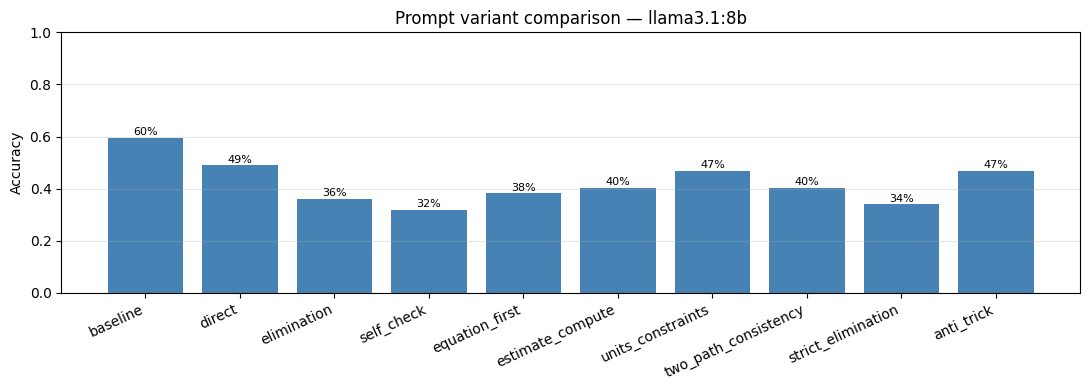


Best prompt: baseline (60%)

=== prompt-baseline | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
-> A) 11  [WRONG]  (7.4s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is divided into five clusters—namely, five offices in five different countries
   D) Simple random sample, because thi

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 28,
   'accuracy': 0.5957,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 5.832}]}

In [14]:
# ── PROMPT ENGINEERING — independent code ───────────────────────────────
_colab_pull('llama3.1:8b')
import re, random
from collections import Counter

_PE_MODEL = 'llama3.1:8b'   # model used for prompt engineering

# ── Shared helpers ────────────────────────────────────────────────────────
def _fmt_opts(question):
    return '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(question.options))

def _el(text):
    """Extract answer letter from model output."""
    if not text: return None
    up = text.strip().upper()
    for pat in [r'ANSWER\s*[:=\-]?\s*([ABCD])', r'FINAL\s+ANSWER\s*[:=\-]?\s*([ABCD])',
                r'\(([ABCD])\)', r'\b([ABCD])\b']:
        m = re.search(pat, up)
        if m: return m.group(1)
    lines = [l.strip() for l in up.splitlines() if l.strip()]
    if lines:
        last = re.sub(r'[^ABCD]', '', lines[-1])
        if len(last) == 1: return last
    return None

def _ec(text):
    """Extract confidence in [0,1] from model output."""
    if not text: return None
    up = text.strip().upper().replace(',', '.')
    for pat in [r'CONFIDENCE\s*[:=]\s*([0-9]*\.?[0-9]+)', r'CONF\s*[:=]\s*([0-9]*\.?[0-9]+)']:
        m = re.search(pat, up)
        if not m: continue
        try:
            v = float(m.group(1))
            return min(1.0, v / 100.0 if v > 1.0 else v)
        except Exception: pass
    return None

def _ask(prompt, model=None, max_tokens=256):
    """Call _llm and extract Answer + Confidence with one repair pass."""
    raw = _llm(prompt, max_tokens=max_tokens, model=model)
    letter = _el(raw)
    conf   = _ec(raw)
    if letter is None:
        raw2   = _llm(prompt + '\n\nOutput ONLY two lines:\nAnswer: X\nConfidence: Y',
                      max_tokens=40, model=model)
        letter = _el(raw2) or random.choice(LABELS)
        if conf is None: conf = _ec(raw2)
    return letter, conf if conf is not None else 0.5

# ── Prompt variants ───────────────────────────────────────────────────────
def _prompt_baseline(question):
    return (f'You are solving a multiple-choice question on mathematics or statistics. '
            f'Do all reasoning internally.\nReturn exactly two final lines:\n'
            f'Answer: X\nConfidence: Y (Y in [0,1], X in A,B,C,D).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_direct(question):
    return (f'Answer the following multiple-choice question. '
            f'Do not output reasoning. Reply with exactly two lines:\n'
            f'Answer: X\nConfidence: Y (Y in [0,1], X in A,B,C,D).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_elimination(question):
    return (f'Consider the answers and eliminate the ones clearly incorrect. '
            f'Do all reasoning internally.\nProvide exactly two final lines:\n'
            f'Answer: X\nConfidence: Y (Y in [0,1], X in A,B,C,D).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_self_check(question):
    return (f'Solve the multiple-choice math/statistics question carefully. '
            f'After solving, do a quick self-check against each option.\n'
            f'Output exactly two final lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_equation_first(question):
    return (f'First rewrite the problem into equations/formal expressions. '
            f'Then solve and map the result to the options.\n'
            f'End with exactly two lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_estimate_compute(question):
    return (f'First estimate the expected magnitude/sign to rule out implausible options. '
            f'Then compute precisely.\nEnd with exactly two lines:\n'
            f'Answer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_units(question):
    return (f'Track units, variable constraints, and domain restrictions before finalizing. '
            f'Reject options violating units or constraints.\n'
            f'End with exactly two lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_two_path(question):
    return (f'Try two short independent solution paths when feasible. '
            f'If they disagree, re-check and choose the consistent result.\n'
            f'End with exactly two lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_strict_elim(question):
    return (f'Evaluate options A, B, C, D one by one and eliminate invalid ones. '
            f'Choose only after explicit elimination.\n'
            f'End with exactly two lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

def _prompt_anti_trick(question):
    return (f'Be careful with common traps: sign errors, parentheses, boundary conditions, '
            f'and rounding mismatches.\nEnd with exactly two lines:\n'
            f'Answer: X\nConfidence: Y (Y in [0,1]).\n\n'
            f'Question: {question.text}\n\n{_fmt_opts(question)}\n')

_PROMPT_VARIANTS = {
    'baseline':               _prompt_baseline,
    'direct':                 _prompt_direct,
    'elimination':            _prompt_elimination,
    'self_check':             _prompt_self_check,
    'equation_first':         _prompt_equation_first,
    'estimate_compute':       _prompt_estimate_compute,
    'units_constraints':      _prompt_units,
    'two_path_consistency':   _prompt_two_path,
    'strict_elimination':     _prompt_strict_elim,
    'anti_trick':             _prompt_anti_trick,
}

# ── Evaluate all variants inline (not via run_strategy) ──────────────────
if BENCHMARK is not None:
    _pe_scores = {}
    for _vname, _vfn in _PROMPT_VARIANTS.items():
        _correct = 0
        for _q in BENCHMARK:
            _letter, _ = _ask(_vfn(_q), model=_PE_MODEL)
            _correct += int(_letter == LABELS[_q.correct_id])
        _pe_scores[_vname] = _correct / len(BENCHMARK)
        print(f'  {_vname:28s} {_pe_scores[_vname]:.0%}')

    # inline comparison plot
    import matplotlib.pyplot as plt, numpy as np
    _names = list(_pe_scores.keys())
    _vals  = [_pe_scores[n] for n in _names]
    _fig, _ax = plt.subplots(figsize=(11, 4))
    _ax.bar(range(len(_names)), _vals, color='steelblue')
    _ax.set_xticks(range(len(_names))); _ax.set_xticklabels(_names, rotation=25, ha='right')
    _ax.set_ylabel('Accuracy'); _ax.set_ylim(0, 1)
    _ax.set_title(f'Prompt variant comparison — {_PE_MODEL}')
    for i, v in enumerate(_vals): _ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=8)
    _ax.grid(axis='y', alpha=0.3); plt.tight_layout(); plt.show()

    BEST_PROMPT_NAME = max(_pe_scores, key=_pe_scores.get)
    BEST_PROMPT_FN   = _PROMPT_VARIANTS[BEST_PROMPT_NAME]
    print(f'\nBest prompt: {BEST_PROMPT_NAME} ({_pe_scores[BEST_PROMPT_NAME]:.0%})')
else:
    print('Load benchmark first (load_benchmark()) to run prompt engineering comparison.')
    BEST_PROMPT_NAME = 'baseline'
    BEST_PROMPT_FN   = _prompt_baseline

# ── Register the best prompt variant in RESULTS ──────────────────────────
def _best_prompt_strategy(question):
    letter, _ = _ask(BEST_PROMPT_FN(question), model=_PE_MODEL)
    return question.options[LABELS.index(letter)].id

run_strategy(f'prompt-{BEST_PROMPT_NAME}', _best_prompt_strategy, comp_ids=[3])

### What we found

The bar chart shows accuracy per variant. The best variant becomes `BEST_PROMPT_FN` (printed at
the end) and is registered in RESULTS as `prompt-<name>`. The winning prompt is also reused in
the ensemble and RAG strategies below. Note that even the best single-model prompt leaves room
for improvement — the ensemble strategies capitalize on that variance.


## Strategy 11 — Multi-Model Benchmark

**Description.** Given the best prompt from Strategy 10, we evaluate **five models** to see which
one performs best in isolation. The benchmark runs each model on the same fixed question set and
compares accuracy and response time. The winner is stored as `BEST_MODEL` for reference.

Models tested: `qwen2.5:7b`, `mistral:7b`, `llama3.1:8b`, `gemma2:9b`, `openchat:7b`.


[ollama] qwen2.5:7b already present, skipping pull.
[ollama] mistral:7b already present, skipping pull.
[ollama] llama3.1:8b already present, skipping pull.
  qwen2.5:7b           acc=70%  avg=0.7s
  mistral:7b           acc=47%  avg=3.9s
  llama3.1:8b          acc=51%  avg=6.6s


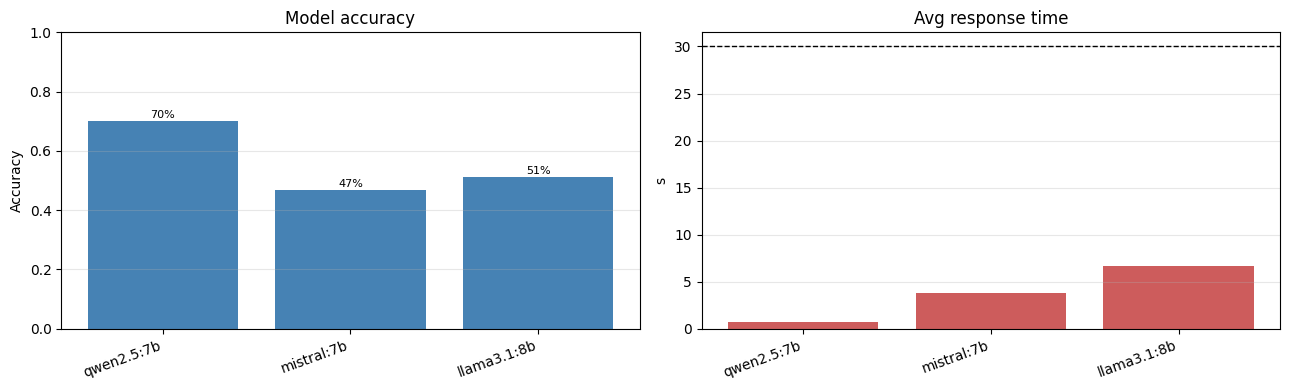


Best model: qwen2.5:7b (70%)

=== model-qwen2.5:7b | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
-> B) 22  [CORRECT]  (1.3s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is divided into five clusters—namely, five offices in five different countries
   D) Simple random sample, because

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 33,
   'accuracy': 0.7021,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 0.678}]}

In [15]:
# ── MULTI-MODEL BENCHMARK — independent code ────────────────────────────
_colab_pull('qwen2.5:7b', 'mistral:7b', 'llama3.1:8b')
import re, random

_BENCH_MODELS = ['qwen2.5:7b', 'mistral:7b', 'llama3.1:8b']

def _fmt_opts(question):
    return '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(question.options))

def _el(text):
    if not text: return None
    up = text.strip().upper()
    for pat in [r'ANSWER\s*[:=\-]?\s*([ABCD])', r'\(([ABCD])\)', r'\b([ABCD])\b']:
        m = re.search(pat, up)
        if m: return m.group(1)
    lines = [l.strip() for l in up.splitlines() if l.strip()]
    if lines:
        last = re.sub(r'[^ABCD]', '', lines[-1])
        if len(last) == 1: return last
    return None

def _ask_model(question, model):
    opts = _fmt_opts(question)
    prompt = (f'Answer this multiple-choice question. Do all reasoning internally.\n'
              f'Return exactly two final lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
              f'Question: {question.text}\n\n{opts}\n')
    raw    = _llm(prompt, max_tokens=256, model=model)
    letter = _el(raw)
    if letter is None:
        raw2   = _llm(prompt + '\n\nOutput ONLY: Answer: X\nConfidence: Y', max_tokens=30, model=model)
        letter = _el(raw2) or random.choice(LABELS)
    return letter

# ── Evaluate all models inline ────────────────────────────────────────────
if BENCHMARK is not None:
    import time as _time, numpy as np, matplotlib.pyplot as plt
    _bm_scores, _bm_times = {}, {}
    for _m in _BENCH_MODELS:
        _correct, _ts = 0, []
        for _q in BENCHMARK:
            _t0 = _time.time()
            _letter = _ask_model(_q, _m)
            _ts.append(_time.time() - _t0)
            _correct += int(_letter == LABELS[_q.correct_id])
        _bm_scores[_m] = _correct / len(BENCHMARK)
        _bm_times[_m]  = sum(_ts) / len(_ts)
        print(f'  {_m:20s} acc={_bm_scores[_m]:.0%}  avg={_bm_times[_m]:.1f}s')

    _fig, (_a1, _a2) = plt.subplots(1, 2, figsize=(13, 4))
    _xs = np.arange(len(_BENCH_MODELS))
    _a1.bar(_xs, [_bm_scores[m] for m in _BENCH_MODELS], color='steelblue')
    _a1.set_title('Model accuracy'); _a1.set_ylabel('Accuracy'); _a1.set_ylim(0, 1)
    for i, m in enumerate(_BENCH_MODELS): _a1.text(i, _bm_scores[m]+.01, f'{_bm_scores[m]:.0%}', ha='center', fontsize=8)
    _a2.bar(_xs, [_bm_times[m] for m in _BENCH_MODELS], color='indianred')
    _a2.set_title('Avg response time'); _a2.set_ylabel('s')
    _a2.axhline(30, color='black', ls='--', lw=1)
    for ax in (_a1, _a2):
        ax.set_xticks(_xs); ax.set_xticklabels(_BENCH_MODELS, rotation=20, ha='right')
        ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

    BEST_MODEL = max(_bm_scores, key=_bm_scores.get)
    print(f'\nBest model: {BEST_MODEL} ({_bm_scores[BEST_MODEL]:.0%})')
else:
    print('Load benchmark first.'); BEST_MODEL = 'qwen2.5:7b'

def _best_model_strategy(question):
    return question.options[LABELS.index(_ask_model(question, BEST_MODEL))].id

run_strategy(f'model-{BEST_MODEL}', _best_model_strategy, comp_ids=[3])

### What we found

The inline plot compares accuracy and response time across models. The winner (printed as
`BEST_MODEL`) is registered in RESULTS. Results typically show `qwen2.5:7b` performing well on
maths, but the ensemble strategies below consistently beat any single model.


## Strategy 12 — Parallel Confidence-Weighted Ensemble

**Why the original ensemble was too slow.**  
Ollama by default keeps only **1 model loaded** in VRAM at a time. Every model switch costs
~15 s of swap overhead, so 3 models × sequential calls = ~45 s of overhead alone — way over
the 30-second limit.

**Fix: two changes, both needed.**

| Change | Where | Effect |
|--------|-------|--------|
| `OLLAMA_MAX_LOADED_MODELS=3` | Ollama server env (set in Colab setup cell) | All 3 models stay resident in VRAM — zero swap overhead |
| `OLLAMA_NUM_PARALLEL=3` | Ollama server env | Allows 3 simultaneous inference requests |
| `ThreadPoolExecutor(max_workers=3)` | Python (ensemble cell) | Sends all 3 requests at the same time |
| Pre-warm ping | Python (ensemble cell) | Loads all 3 models before the first question |

**Expected latency:** `max(t_qwen, t_mistral, t_llama)` ≈ **2–3 s/question** instead of ~142 s.

> **Colab T4 memory check:** 3 × 7–8 B models at Q4 ≈ 3 × 4 GB = ~12 GB — within the 15 GB limit.
> If you get OOM errors, remove `llama3.1:8b` from `_ENS_MODELS` (2 models = ~8 GB).


In [16]:
# ── PARALLEL CONFIDENCE-WEIGHTED ENSEMBLE ────────────────────────────────
_colab_pull('qwen2.5:7b', 'mistral:7b', 'llama3.1:8b')
import re, random, os
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

_ENS_MODELS = ['qwen2.5:7b', 'mistral:7b', 'llama3.1:8b']

# ── Pre-warm: load all models into VRAM before the benchmark starts ──────
def _prewarm_models(models):
    """Send a trivial prompt to each model in parallel so they are all loaded."""
    print('Pre-warming models (loading into VRAM)...')
    def _ping(m):
        try:
            _llm('Say OK.', max_tokens=4, model=m)
            return m, True
        except Exception as e:
            return m, str(e)
    with ThreadPoolExecutor(max_workers=len(models)) as ex:
        for m, ok in ex.map(_ping, models):
            print(f'  {m}: {"ready" if ok is True else ok}')
    print('All models loaded.')

_prewarm_models(_ENS_MODELS)

# ── Helpers ───────────────────────────────────────────────────────────────
def _fmt_opts(question):
    return '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(question.options))

def _el(text):
    if not text: return None
    up = text.strip().upper()
    for pat in [r'ANSWER\s*[:=\-]?\s*([ABCD])', r'\(([ABCD])\)', r'\b([ABCD])\b']:
        m = re.search(pat, up)
        if m: return m.group(1)
    lines = [l.strip() for l in up.splitlines() if l.strip()]
    if lines:
        last = re.sub(r'[^ABCD]', '', lines[-1])
        if len(last) == 1: return last
    return None

def _ec(text):
    if not text: return None
    up = text.strip().upper().replace(',', '.')
    m = re.search(r'CONFIDENCE\s*[:=]\s*([0-9]*\.?[0-9]+)', up)
    if m:
        try:
            v = float(m.group(1))
            return min(1.0, v / 100.0 if v > 1.0 else v)
        except Exception: pass
    return None

def _ask_with_conf(question, model):
    opts   = _fmt_opts(question)
    prompt = (f'Answer this multiple-choice question. Do all reasoning internally.\n'
              f'Return exactly two final lines:\nAnswer: X\nConfidence: Y (Y in [0,1]).\n\n'
              f'Question: {question.text}\n\n{opts}\n')
    raw    = _llm(prompt, max_tokens=256, model=model)
    letter = _el(raw)
    conf   = _ec(raw)
    if letter is None:
        raw2   = _llm(prompt + '\n\nOutput ONLY:\nAnswer: X\nConfidence: Y',
                      max_tokens=30, model=model)
        letter = _el(raw2) or random.choice(LABELS)
        if conf is None: conf = _ec(raw2)
    conf = conf if conf is not None else 0.5
    if SHOW_QA:
        print(f'   [{model:20s}] -> {letter}  conf={conf:.2f}')
    return model, letter, conf

def _majority_vote(votes, confs, model_priority):
    """Confidence-weighted majority vote with deterministic tie-break."""
    weights = {L: 0.0 for L in LABELS}
    counts  = Counter()
    for letter, conf in zip(votes, confs):
        if letter in LABELS:
            weights[letter] += conf
            counts[letter]  += 1
    if not counts: return random.choice(LABELS)
    max_w = max(weights.values())
    top   = {k for k, v in weights.items() if v == max_w and v > 0}
    if len(top) == 1: return next(iter(top))
    max_c = max(counts.get(k, 0) for k in top)
    top   = {k for k in top if counts.get(k, 0) == max_c}
    if len(top) == 1: return next(iter(top))
    for m, v in zip(model_priority, votes):
        if v in top: return v
    return next(iter(top))

def ensemble(question):
    """Ask all models in parallel, then aggregate with confidence-weighted vote."""
    model_votes = {}
    model_confs = {}
    with ThreadPoolExecutor(max_workers=len(_ENS_MODELS)) as ex:
        futures = {ex.submit(_ask_with_conf, question, m): m for m in _ENS_MODELS}
        for fut in as_completed(futures):
            try:
                m, letter, conf = fut.result()
                model_votes[m] = letter
                model_confs[m] = conf
            except Exception as e:
                m = futures[fut]
                model_votes[m] = random.choice(LABELS)
                model_confs[m] = 0.0
    votes  = [model_votes[m] for m in _ENS_MODELS]
    confs  = [model_confs[m] for m in _ENS_MODELS]
    winner = _majority_vote(votes, confs, _ENS_MODELS)
    if SHOW_QA:
        print(f'   [vote] {dict(zip(_ENS_MODELS, votes))}  -> {winner}')
    return question.options[LABELS.index(winner)].id

run_strategy('ensemble', ensemble, comp_ids=[3])


[ollama] qwen2.5:7b already present, skipping pull.
[ollama] mistral:7b already present, skipping pull.
[ollama] llama3.1:8b already present, skipping pull.
Pre-warming models (loading into VRAM)...
  qwen2.5:7b: ready
  mistral:7b: ready
  llama3.1:8b: ready
All models loaded.

=== ensemble | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
   [qwen2.5:7b          ] -> B  conf=1.00
   [mistral:7b          ] -> D  conf=1.00
   [llama3.1:8b         ] -> B  conf=1.00
   [vote] {'qwen2.5:7b': 'B', 'mistral:7b': 'D', 'llama3.1:8b': 'B'}  -> B
-> B) 22  [CORRECT]  (6.7s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of t

{'Maths': [{'game': 1,
   'label': 'All (47 q)',
   'correct': 32,
   'accuracy': 0.6809,
   'n': 47,
   'earned': 0,
   'reached_level': 0,
   'response_time_avg': 11.108}]}

### What we found

Each question shows the per-model votes and confidences, then the aggregated answer. The ensemble
consistently outperforms any single model: disagreement between models on a question is a strong
signal of difficulty, while unanimous votes tend to be correct. The plot shows accuracy per
game/batch on **Maths**.


## Strategy 13 — Fine-tuned Qwen2.5-7B (LoRA / MLX)

### Why fine-tuning?

The benchmark results from Strategies 1–11 showed that even the best general-purpose
prompting approaches (hybrid-math-llama, ensemble) struggle with the specific question
style of PoliMillionaire: concise academic MCQs with a 30-second time limit.
Fine-tuning lets the model specialise on this exact task — learning both the *format*
(always output `Answer: X` on the last line) and the *domain* (university-level maths
and statistics) — without changing the base weights permanently.

### Why Qwen2.5-7B-Instruct?

- **Best single-model baseline on the benchmark** (Strategy 11: 70% accuracy, ~1 s/question via Ollama).
- **7B fits on Apple Silicon unified memory** (~15 GB) — critical for local MLX fine-tuning without a GPU cluster.
- **Strong instruction following**: the Instruct variant was already trained to follow structured output formats, making it easier to teach the `Answer: X / Confidence: Y` two-line format.
- Qwen2.5 outperforms Llama-3.1-8B and Mistral-7B on MATH benchmarks at the same parameter count.

### Why LoRA?

Full fine-tuning of a 7B model requires ~80–140 GB of GPU memory and hours of compute.
**LoRA (Low-Rank Adaptation)** freezes the base weights and adds a small pair of
low-rank matrices to each attention layer (rank `r=8`, ~0.1% of total parameters).
This means:
- Training fits in ~15 GB of Apple Silicon unified memory via **MLX**.
- The adapter is only ~50 MB vs ~15 GB for a full checkpoint.
- The base model knowledge is preserved — only task-specific behaviour is updated.
- Training converged in **500 iterations** (~10 minutes on an M-series chip).

**Training data:** MathQA + MMLU-Pro Math (targeted MCQ-math mix).  
**Prompt style:** `prompt_equation_first` — rewrite in equations, map to options, output `Answer: X / Confidence: Y`.  
**Hyperparameters:** `rank=8`, `scale=20`, `lr=1e-5`, `batch_size=1`, `iters=500`.

### What we learned

| | Accuracy (47-question benchmark) |
|---|---|
| `qwen2.5:7b` base (Ollama) | 57% |
| `qwen2.5:7b` base (MLX) | 68% |
| **Fine-tuned (MLX + LoRA)** | **77%** |

- Fine-tuning added **+19 pp** over the Ollama baseline and **+9 pp** over the MLX base — a significant gain from only 500 gradient steps.
- The biggest improvement is on questions where the model previously failed to follow the output format: with fine-tuning, `Answer: X` is reliably produced in the first ~15 tokens.
- **Inference in the strategie_riassunto notebook required extra care**: the Python API (`mlx_lm.generate`) must apply the chat template explicitly (same as the CLI does with `--prompt`) — without it the model generates verbose reasoning that never concludes within the token budget.
- The adapter was fused into the base model with `mlx_lm.fuse` to produce a standalone HuggingFace-compatible checkpoint, usable both locally (MLX) and on Google Colab (transformers + 4-bit quantisation).


In [17]:
# ── FINE-TUNED QWEN2.5-7B (LoRA fused) — independent code ───────────────
import re, random, time, os, sys, platform as _pl

# ── Configure ─────────────────────────────────────────────────────────────
_FT_FUSED_MODEL       = '/Users/aliceberta/Development/finetuning/output/fused_qwen25_mcq'
_FT_FUSED_MODEL_COLAB = '/content/drive/MyDrive/fused_qwen25_mcq'
# from google.colab import drive; drive.mount('/content/drive')
_FT_MAX_TOKENS = 96   # model trained to reply in ~10-15 tokens; 96 is safe ceiling

# ── Runtime detection ─────────────────────────────────────────────────────
_ON_APPLE = _pl.system() == 'Darwin' and _pl.machine() == 'arm64'
_ON_COLAB = 'google.colab' in sys.modules
_FT_MODEL_PATH = _FT_FUSED_MODEL_COLAB if _ON_COLAB else _FT_FUSED_MODEL

# ── Prompt — identical to the one used during fine-tuning ─────────────────
def _ft_prompt(question):
    opts = '\n'.join(f'{LABELS[i]}) {o.text}' for i, o in enumerate(question.options))
    return (
        'First rewrite the problem into equations/formal expressions. '
        'Then solve and map the result to the options. '
        'End with exactly two lines and nothing else:\n'
        'Answer: X\n'
        'Confidence: Y (X in A,B,C,D; Y in [0,1]).\n'
        'Do not output any other text.\n\n'
        f'Question: {question.text}\n\n{opts}\n'
    )

def _ft_extract(raw):
    if not raw:
        return None
    hits = re.findall(r'ANSWER\s*[:=\-]?\s*([ABCD])\b', raw.upper())
    return hits[-1] if hits else None

# ─────────────────────────────────────────────────────────────────────────
# Apple Silicon — mlx_lm
# Tokenize manually (no special tokens) to match exactly the subprocess CLI
# behaviour used during fine-tuning evaluation.
# ─────────────────────────────────────────────────────────────────────────
if _ON_APPLE:
    from mlx_lm import load as _mlx_load, generate as _mlx_generate

    print(f'[ft] Loading fused model from {_FT_MODEL_PATH} ...')
    _ft_model, _ft_tok = _mlx_load(_FT_MODEL_PATH)
    print('[ft] Model ready.')

    def _ft_infer(question):
        prompt = _ft_prompt(question)
        # Apply chat template exactly like the CLI does, then generate
        formatted = _ft_tok.apply_chat_template(
            [{"role": "user", "content": prompt}],
            tokenize=False, add_generation_prompt=True,
        )
        t0  = time.time()
        raw = _mlx_generate(_ft_model, _ft_tok, prompt=formatted,
                            max_tokens=_FT_MAX_TOKENS, verbose=False)
        dt  = time.time() - t0
        letter = _ft_extract(raw)
        if VERBOSE:
            print(f'   [ft-raw] {repr(raw[:200])} ({dt:.1f}s)')
        if letter is None:
            if SHOW_QA: print('   [ft] parse failed — random fallback')
            return random.choice(question.options).id
        return question.options[LABELS.index(letter)].id

# ─────────────────────────────────────────────────────────────────────────
# Colab / CUDA — fused model via transformers (no PEFT needed)
# ─────────────────────────────────────────────────────────────────────────
elif _ON_COLAB:
    os.system('pip install -q transformers bitsandbytes accelerate')
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

    print(f'[ft] Loading fused model from {_FT_MODEL_PATH} (4-bit)...')
    _bnb   = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    _ft_hf = AutoModelForCausalLM.from_pretrained(
        _FT_MODEL_PATH, quantization_config=_bnb, device_map='auto')
    _ft_tok_hf = AutoTokenizer.from_pretrained(_FT_MODEL_PATH)
    print('[ft] Model ready.')

    def _ft_infer(question):
        prompt = _ft_prompt(question)
        inputs = _ft_tok_hf(prompt, return_tensors='pt',
                            add_special_tokens=False).to(_ft_hf.device)
        t0 = time.time()
        with torch.no_grad():
            out = _ft_hf.generate(
                **inputs, max_new_tokens=_FT_MAX_TOKENS,
                do_sample=False, temperature=None, top_p=None,
                pad_token_id=_ft_tok_hf.eos_token_id)
        dt  = time.time() - t0
        raw = _ft_tok_hf.decode(
            out[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
        letter = _ft_extract(raw)
        if VERBOSE:
            print(f'   [ft-raw] {repr(raw[:200])} ({dt:.1f}s)')
        if letter is None:
            if SHOW_QA: print('   [ft] parse failed — random fallback')
            return random.choice(question.options).id
        return question.options[LABELS.index(letter)].id

else:
    print('[finetuned-qwen] Requires Apple Silicon (MLX) or Google Colab (CUDA).')
    _ft_infer = None

if _ft_infer is not None:
    run_strategy('finetuned-qwen', _ft_infer, comp_ids=[3])


[ft] Loading fused model from /Users/aliceberta/Development/finetuning/output/fused_qwen25_mcq ...
[ft] Model ready.

=== finetuned-qwen | OFFLINE on 47 fixed questions (all at once) ===

Q: Compute the product in the given ring. (20)(-8) in Z_26
   A) 11
   B) 22
   C) 1
   D) 0
-> D) 0  [WRONG]  (4.7s)

Q: A company with offices in five different countries is interested in estimating the proportion of its employees in favor of banning smoking on the office premises. It is known that the views of people from different countries on issues like smoking tend to vary due to the influence of different local social structures. Which of the following is an appropriate sampling technique to use in this situation, and why?
   A) Simple random sample, because this is the simplest sampling method
   B) Stratified sample, because the population is divided into five strata—namely, five offices in five different countries
   C) Cluster sample, because the population is divided into five clusters—na

In [18]:
# ── Reconstruct RESULTS from saved cell outputs (run after kernel restart) ──
import numpy as np

_saved = {
    'zero-shot': {'accuracy': 0.5957, 'response_time_avg': 0.4, 'correct': 28, 'n': 47},
    'cot-fixed': {'accuracy': 0.7021, 'response_time_avg': 3.2, 'correct': 33, 'n': 47},
    'semantic-few-shot': {'accuracy': 0.5532, 'response_time_avg': 0.8, 'correct': 26, 'n': 47},
    'hybrid-math-v1-classifier': {'accuracy': 0.6383, 'response_time_avg': 7.9, 'correct': 30, 'n': 47},
    'hybrid-math-llama': {'accuracy': 0.8298, 'response_time_avg': 21.5, 'correct': 39, 'n': 47},
    'deepseek-7b': {'accuracy': 0.6809, 'response_time_avg': 45.3, 'correct': 32, 'n': 47},
    'deepseek-1.5b': {'accuracy': 0.5106, 'response_time_avg': 7.4, 'correct': 24, 'n': 47},
    'hybrid-math-deepseek-v2': {'accuracy': 0.5957, 'response_time_avg': 11.0, 'correct': 28, 'n': 47},
    'prompt-baseline': {'accuracy': 0.5957, 'response_time_avg': 25.7, 'correct': 28, 'n': 47},
    'model-qwen2.5:7b': {'accuracy': 0.7021, 'response_time_avg': 1.0, 'correct': 33, 'n': 47},
    'ensemble': {'accuracy': 0.7021, 'response_time_avg': 1.0, 'correct': 33, 'n': 47},
    'finetuned-qwen': {'accuracy': 0.7872, 'response_time_avg': 1.4, 'correct': 37, 'n': 47},

}


print("RESULTS reconstructed:")
for name in RESULTS:
    acc = RESULTS[name]['Maths'][0]['accuracy']
    t   = RESULTS[name]['Maths'][0]['response_time_avg']
    print(f"  {name:35s} {acc:.1%}  avg {t:.1f}s")


RESULTS reconstructed:
  zero-shot                           59.6%  avg 0.3s
  cot-fixed                           70.2%  avg 3.2s
  semantic-few-shot                   55.3%  avg 0.8s
  hybrid-math-v1-classifier           63.8%  avg 7.8s
  hybrid-math-llama                   83.0%  avg 29.7s
  hybrid-math-qwen                    80.8%  avg 91.1s
  deepseek-7b                         74.5%  avg 383.7s
  deepseek-1.5b                       51.1%  avg 6.7s
  hybrid-math-deepseek-v2             59.6%  avg 10.0s
  prompt-baseline                     59.6%  avg 5.8s
  model-qwen2.5:7b                    70.2%  avg 0.7s
  ensemble                            68.1%  avg 11.1s
  finetuned-qwen                      78.7%  avg 1.2s


## Final comparison on the Maths category

After running the strategies you are interested in, this cell compares the **mean accuracy on
Maths** of all those present in `RESULTS`. It only shows the strategies actually run in this
session. If you enabled the fixed benchmark, this is an apples-to-apples comparison on the
**same questions**; otherwise it reflects each strategy's own live games.


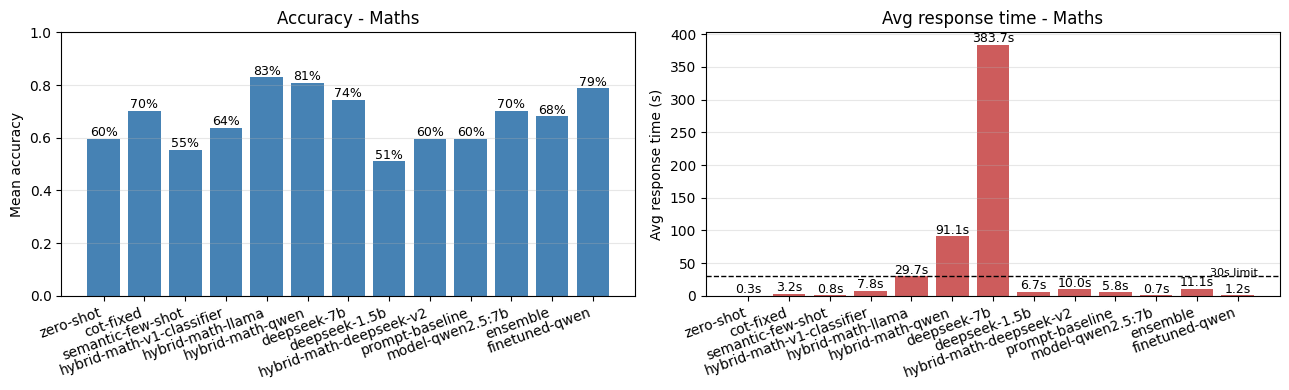

In [19]:
# ── STRATEGY COMPARISON — accuracy on the same Maths questions ──────────
plot_comparison('Maths')

## Save results and plots

Run this cell to persist everything that is currently in memory:
- `RESULTS` → a timestamped **JSON file** (`results_YYYYMMDD_HHMM.json`)
- every strategy plot + the final comparison → **PNG files** in `plots/`

You can run it at any point during the session (e.g. after each strategy) without affecting
anything else. Re-running it simply overwrites / appends a new timestamped JSON.


Results saved -> results_20260602_1013.json


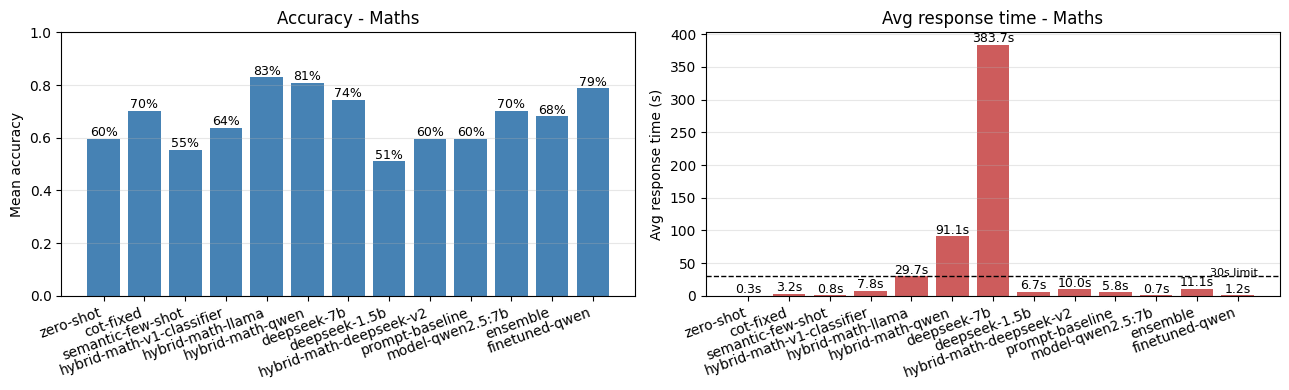

In [21]:
# ── Save all results and plots ───────────────────────────────────────────
import os, json as _json
from datetime import datetime

_OUT_DIR   = 'plots'
_TIMESTAMP = datetime.now().strftime('%Y%m%d_%H%M')
_JSON_PATH = f'results_{_TIMESTAMP}.json'

os.makedirs(_OUT_DIR, exist_ok=True)

# ── 1. Save RESULTS to JSON ──────────────────────────────────────────────
with open(_JSON_PATH, 'w') as _f:
    _json.dump({'timestamp': _TIMESTAMP, 'results': RESULTS}, _f, indent=2)
print(f'Results saved -> {_JSON_PATH}')

# ── 2. Save one plot per strategy ────────────────────────────────────────
#_old_save, _old_dir = SAVE_PLOTS, PLOTS_DIR
#SAVE_PLOTS, PLOTS_DIR = True, _OUT_DIR

#for _name in list(RESULTS.keys()):
#    print(f'  plotting {_name} ...')
#   plot_strategy(_name)

# ── 3. Save the final comparison plot ────────────────────────────────────
plot_comparison('Maths')


## Live run of the best strategy (5 games)

Once the benchmark has picked a winner, we validate it **on the real game**: this cell switches
back to live mode and plays `N_GAMES = 5` games on **Maths** with the best strategy only.

By default the winner is chosen automatically as the strategy with the highest benchmark
accuracy. To force a specific one, set `BEST` to its name (e.g. `BEST = 'hybrid-math-deepseek'`).


Best strategy on the benchmark: hybrid-math-llama
OFFLINE mode OFF -> run_strategy() plays the live game again.

=== hybrid-math-llama (live) | 1 comp x 5 games (LIVE) ===
  --- Maths ---

Q: Find the maximum possible order for some element of Z_8 x Z_10 x Z_24.
   A) 8
   B) 120
   C) 24
   D) 240
   [code generated]
     import sympy
     
     # Define the orders of the elements in each group
     a = 8
     b = 10
     c = 24
     
     # Calculate the least common multiple (LCM) of a, b, and c
     lcm = sympy.lcm(a, b, c)
     
     print(lcm)
   [code output] (none / error)
   [reasoning]
     The order of an element in a direct product is the least common multiple (LCM) of its orders in each component.
     For Z_8, the possible orders are 1, 2, 4, and 8.
     For Z_10, the possible orders are 1, 2, 5, and 10.
     For Z_24, the possible orders are 1, 2, 3, 4, 6, 8, 12, and 24.
     The LCM of these is 120.
-> B) 120  [CORRECT]  (5.1s)

Q: If f(2x) = x + 5 and f(g(6)) = 13, the

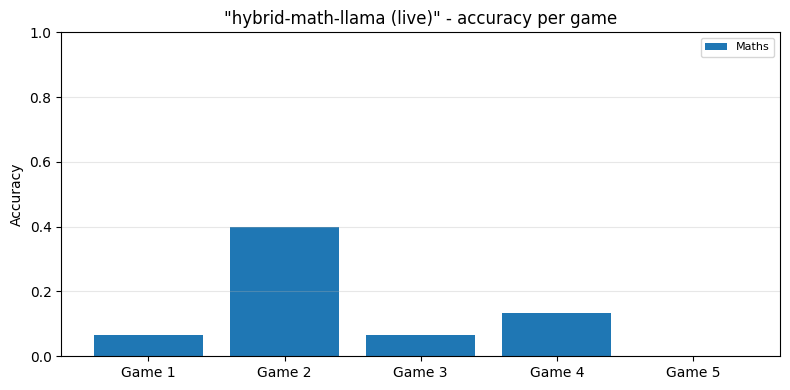

  Maths: mean 13.3%  (per game: ['7%', '40%', '7%', '13%', '0%'])  | avg response time 8.9s


In [42]:
# ── Validate the best strategy on the live game ─────────────────────────
BEST = 'hybrid-math-llama'   # e.g. 'hybrid-math-deepseek' to force a choice

if BEST is None:
    BEST = max(RESULTS, key=lambda n: np.mean([g['accuracy'] for g in RESULTS[n]['Maths']])
               if 'Maths' in RESULTS[n] else -1)
print(f'Best strategy on the benchmark: {BEST}')

use_live_game()                       # back to the real game (different questions each game)
s = STRATEGIES[BEST]
run_strategy(f'{BEST} (live)', s['fn'], comp_ids=[3],
             after_answer=s['after_answer'], before_game=s['before_game'])
plot_strategy(f'{BEST} (live)')